# Social Media Usage and Mental Well-Being

**A data science project using the CDC Youth Risk Behavior Survey (YRBS), 2023**

This notebook studies how social media use, sleep, physical activity and age relate to self-reported mental health among US high-school students.

The data is public, from the U.S. Centers for Disease Control and Prevention (CDC). Every number in this notebook is **calculated from that data when the notebook runs**. No result is typed in by hand.

> **Read this first.** The survey is *cross-sectional*: each student answered once, at one point in time. It can show whether two things tend to go together (an **association**). It cannot show that one thing **causes** the other.

**How to run it:** use *Kernel → Restart & Run All*. The cells depend on each other and must run from top to bottom.

## 2. Problem statement

Social media is part of most teenagers' daily lives. Many people worry that heavy use harms sleep and mental health, while others point out that young people also use it for friendship and support.

This project asks a narrow, testable question. **Among US high-school students in 2023, is social media use frequency associated with sleep duration and self-reported mental health? And how do physical activity and age fit into that picture?**

## 3. Motivation and objectives

**Why it matters:** adolescence is a key period for sleep and mental health. Knowing which habits tend to go together helps schools, parents and researchers decide what to study more closely.

The project began with seven objectives. After checking which questions the 2023 YRBS actually asks, each was marked as supported or not:

| # | Original objective | Status in this dataset |
|---|---|---|
| 1 | Analyse daily social media usage and screen time | **Partial**: social media *frequency* only. No screen-time question |
| 2 | Screen time vs sleep duration | **Replaced** by social media frequency vs sleep duration |
| 3 | Nighttime social media use vs sleep quality | **Not possible**: neither is measured |
| 4 | Physical activity vs self-reported well-being | **Supported** |
| 5 | Social media habits across age groups | **Supported** (ages about 14–18 only) |
| 6 | Social media use vs self-reported anxiety | **Replaced**: no anxiety question. Poor mental health and persistent sadness are used and labelled as such |
| 7 | Correlation heatmap and statistical analysis | **Supported** |

## 4. Research questions

- **RQ1.** How often do US high-school students use social media, and does this differ by sex, age and grade?
- **RQ2.** Is social media use frequency associated with hours of sleep on school nights?
- **RQ3.** Is physical activity associated with self-reported mental health (poor mental health, persistent sadness)?
- **RQ4.** Do social media habits differ across age groups?
- **RQ5.** Is social media use frequency associated with poor mental health, persistent sadness and difficulty concentrating?
- **RQ6.** How are these variables correlated with each other?
- **RQ7.** How well can these behaviours *predict* poor mental health, and what rule-based well-being suggestions follow from a student's answers? This is prediction, not explanation.

None of these questions assumes a direction. Each test checks for *any* association, positive or negative.

## 5. Dataset source and data dictionary

| | |
|---|---|
| **Dataset** | Youth Risk Behavior Survey (YRBS), 2023 national high-school data |
| **Publisher** | U.S. Centers for Disease Control and Prevention (CDC) |
| **Where** | https://www.cdc.gov/yrbs/data/index.html → 2023 → *ASCII* (`XXH2023_YRBS_Data.dat`) |
| **Who** | A nationally representative sample of students in grades 9–12 in the 50 states and DC |
| **Format** | A fixed-width text file. Column positions come from CDC's SAS input program, saved in `data/raw/documentation/` |
| **License** | CDC's data page lists no license. As US federal government work it is generally public domain in the US. Cite CDC as the source |

**Variables used** (codes and labels from CDC's formats program):

| Concept | CDC variable | Cleaned column(s) | Answer scale |
|---|---|---|---|
| Age | Q1 | `age_label`, `age_group`, `age_code` | 12 or younger … 18 or older |
| Sex | Q2 | `sex` | Female, Male |
| Grade | Q3 | `grade_label` | 9th–12th, ungraded |
| Race/ethnicity | RACEETH | `race_ethnicity` | 8 CDC groups |
| Social media use | Q80 | `social_media_freq`, `social_media_code`, `social_media_frequent` | 8 levels, from *I do not use social media* to *More than once an hour* |
| Sleep | Q85 | `sleep_hours_cat`, `sleep_hours_approx`, `sleep_8plus` | 4 or less … 10 or more hours on a school night |
| Physical activity | Q76 | `active_days`, `active_5plus` | 0–7 days active for 60+ minutes |
| Mental health | Q84 | `poor_mh_frequency`, `poor_mh_code`, `poor_mental_health` | How often mental health was *not good*, past 30 days: Never … Always (**higher = worse**) |
| Persistent sadness | Q26 | `sad_hopeless` | Yes/No, past 12 months |
| Difficulty concentrating | Q106 | `difficulty_concentrating` | Yes/No |
| Survey design | WEIGHT, STRATUM, PSU | `weight`, `stratum`, `psu` | Used to produce national estimates |

**Not available:** screen time, nighttime social media use, sleep quality and anxiety. The full data dictionary is printed in Section 7.

## 6. Importing the libraries

What each library does:
- **pandas** holds the data in a table called a *DataFrame*. Think of it as a spreadsheet in Python.
- **numpy** does fast maths on arrays of numbers.
- **matplotlib** and **seaborn** draw charts.
- **statsmodels** fits the regression model.
- **scikit-learn** trains and evaluates the prediction models (Section 15), through `src/ml_model.py`.

The project also has three modules of its own in `src/`. **The dashboard uses exactly the same ones**, so the notebook and the dashboard always clean and calculate in the same way:
- `data_processing` loads, checks and cleans the CDC file.
- `analysis_utils` has the weighted percentages and the statistical tests (Spearman, chi-square, Mann–Whitney, Kruskal–Wallis).
- `plotting` has the shared colours and reusable chart functions.

In [1]:
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import scipy
import statsmodels
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.multitest import multipletests
from IPython.display import display, Markdown

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")


def find_project_root(start: Path) -> Path:
    """Walk up from the current folder until we find the project (the folder holding src/)."""
    for folder in [start, *start.parents]:
        if (folder / "src" / "data_processing.py").exists():
            return folder
    raise FileNotFoundError(
        "Could not find the project folder (the one containing src/data_processing.py). "
        "Start Jupyter from inside the project folder.")


PROJECT_ROOT = find_project_root(Path.cwd().resolve())
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))  # lets Python find our own 'src' package

from src import data_processing as dp
from src import analysis_utils as au
from src import plotting as pl

pl.apply_style()   # shared chart style (fonts, colours, light grid)

print("Project folder found:", PROJECT_ROOT.name)   # name only, so no personal path is printed
print("Charts are saved to:", pl.CHARTS_DIR.relative_to(PROJECT_ROOT) if pl.CHARTS_DIR.is_relative_to(PROJECT_ROOT)
      else pl.CHARTS_DIR.name)
for module in (pd, np, matplotlib, sns, scipy, statsmodels):
    print(f"{module.__name__:<12} {module.__version__}")

Project folder found: social-media-wellbeing
Charts are saved to: outputs\charts
pandas       3.0.6
numpy        2.5.4
matplotlib   3.11.2
seaborn      0.13.2
scipy        1.18.1
statsmodels  0.15.0


### About the shared helper functions

A few ideas used throughout:

**Why "weighted"?** The YRBS deliberately samples some groups more than others. Each student has a survey **weight**: the number of US students they represent. A *weighted percentage* (`au.weighted_share`, `au.weighted_share_by`) gives a national estimate; a plain count only describes the students in the sample. We show both.

**Confidence intervals (CI):** the 95% CI is a range of plausible values for the national percentage. It is approximated with Kish's *effective sample size*, which shrinks the sample size to account for unequal weights. It ignores the survey's clustering, so the true intervals are somewhat wider.

**Statistical tests** (all in `au`; each returns n, test statistic, p-value and effect size):
- **Spearman's rank correlation (ρ, "rho")** measures whether two *ordered* variables tend to rise together (ρ > 0) or move in opposite directions (ρ < 0), from −1 to +1. We use Spearman instead of Pearson because our variables are ordered categories (for example "Never … Always"), not exact measurements.
- **Chi-square test of independence** checks whether two categorical variables are related. **Cramér's V** (0 to 1) measures how strong the relationship is.
- **Mann–Whitney U** compares an ordered variable between two groups. The **rank-biserial r** (−1 to +1) is its effect size.
- **Kruskal–Wallis H** is the same idea for three or more groups. **Epsilon-squared (ε²)** is its effect size.

**A note on p-values with large samples:** with thousands of students, even tiny differences give very small p-values. Always read the **effect size**, not only the p-value.

You can read any helper's documentation with `help(...)`:

In [2]:
help(au.weighted_share)

Help on function weighted_share in module src.analysis_utils:

weighted_share(flag: 'pd.Series', weight: 'pd.Series') -> 'Tuple[float, float, float, int]'
    Weighted % of 1s in a 0/1 column, approximate 95% CI, and n.

    The CI uses Kish's effective sample size, n_eff = (sum w)^2 / sum(w^2), which accounts
    for unequal weights but not for clustering, so it is somewhat too narrow.



## 7. Loading the raw dataset

CDC provides a **fixed-width text file**. Every value sits at a fixed character position on each line (for example, the social media answer is always character 111). `dp.load_raw_data()`:

1. reads those positions (taken from CDC's SAS program) and saves just the columns we need to a CSV in `data/interim/`
2. loads that CSV with `pd.read_csv`
3. checks that every expected column is present

The original `.dat` file is only read, never changed.

**If this cell fails with "Raw data file not found"**, follow the printed instructions to download the file from CDC first. In short: run `python -m src.download_data`, or download *ASCII* for 2023 from https://www.cdc.gov/yrbs/data/index.html and save it as `data/raw/XXH2023_YRBS_Data.dat`.

In [3]:
raw_df = dp.load_raw_data()          # same function the dashboard's pipeline uses

print(f"Rows (students): {raw_df.shape[0]:,}   Columns: {raw_df.shape[1]}")
raw_df.head()

Rows (students): 20,103   Columns: 20


,row_id,is_duplicate_record,Q1,Q2,Q3,Q26,Q76,Q80,Q84,Q85,Q106,QN26,QN76,QN80,QN84,QN85,WEIGHT,STRATUM,PSU,RACEETH
0,1,False,3,1,1,1,1,6,1,3,2,1,2,1,2,2,0.8614,103,16294,NaN
1,2,False,4,2,1,2,5,4,3,5,1,2,2,2,2,1,0.8920,103,16294,5
2,3,False,5,2,3,1,8,8,2,1,2,1,1,1,2,2,0.5081,103,16294,5
3,4,False,6,1,2,1,3,8,3,4,1,1,2,1,2,2,1.1759,103,16294,5
4,5,False,3,2,1,1,8,6,3,3,2,1,1,1,2,2,0.8920,103,16294,5


`raw_df.head()` shows the first five rows. The values are still **CDC answer codes** ("1", "2", …), not labels. For example, in `Q80` the code "6" means "Several times a day". A blank (`NaN`) means the student did not answer.

The data dictionary comes straight from the project module, so it always matches the code:

In [4]:
fields = pd.DataFrame([{"CDC variable": f.name, "start position": f.start, "width": f.width,
                        "CDC label": f.cdc_label} for f in dp.RAW_FIELDS])
display(Markdown("**Raw fields read from the CDC file**"))
display(fields)
display(Markdown("**Cleaned dataset columns**"))
display(pd.DataFrame(dp.DATA_DICTIONARY))

**Raw fields read from the CDC file**

,CDC variable,start position,width,CDC label
0,Q1,17,1,How old are you
1,Q2,18,1,What is your sex
2,Q3,19,1,In what grade are you
3,Q26,57,1,Sad or hopeless
4,Q76,107,1,Physical activity >= 5 days
5,Q80,111,1,Social media
6,Q84,115,1,Current mental health
7,Q85,116,1,Hours of sleep on school night
8,Q106,137,1,Difficulty concentrating
9,QN26,203,1,Felt sad or hopeless


**Cleaned dataset columns**

,column,source,type,values,description
0,row_id,line number in .dat,integer,1..N,Row position in the CDC file (the file has no ...
1,age_code,Q1,integer (ordinal),1-7,CDC answer code for 'How old are you'.
2,age_label,Q1,ordered category,12 years old or younger; 13 years old; 14 year...,Age in years as answered.
3,age_group,Q1,ordered category,14 or younger; 15; 16; 17; 18 or older,"Age grouped as in CDC MMWR reports (12, 13 and..."
4,sex,Q2,category,Female; Male,'What is your sex'.
5,grade_code,Q3,integer,1-5,CDC answer code for 'In what grade are you' (5...
6,grade_label,Q3,category,9th grade; 10th grade; 11th grade; 12th grade;...,School grade.
7,race_ethnicity,RACEETH,category,Am Indian/Alaska Native; Asian; Black or Afric...,CDC-derived race/ethnicity.
8,social_media_code,Q80,integer (ordinal),1-8,CDC answer code for how often the student uses...
9,social_media_freq,Q80,ordered category,I do not use social media; A few times a month...,Frequency of social media use. This is FREQUEN...


## 8. Data exploration and quality checks

Before any analysis we check:
- **data types**: what pandas thinks each column is
- **missing values**: how many students skipped each question
- **invalid values**: codes outside CDC's official code list
- **duplicates**: identical records
- **outliers**: every answer is a bounded code, so an "outlier" can only be an invalid code. We also look at extreme survey weights
- **consistency**: whether our recoding matches CDC's own pre-computed yes/no indicators (the `QN` variables)

In [5]:
raw_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20103 entries, 0 to 20102
Data columns (total 20 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   row_id               20103 non-null  Int64
 1   is_duplicate_record  20103 non-null  bool 
 2   Q1                   20005 non-null  str  
 3   Q2                   19945 non-null  str  
 4   Q3                   19910 non-null  str  
 5   Q26                  19863 non-null  str  
 6   Q76                  18876 non-null  str  
 7   Q80                  15203 non-null  str  
 8   Q84                  15705 non-null  str  
 9   Q85                  17441 non-null  str  
 10  Q106                 10946 non-null  str  
 11  QN26                 19863 non-null  str  
 12  QN76                 18876 non-null  str  
 13  QN80                 15203 non-null  str  
 14  QN84                 15705 non-null  str  
 15  QN85                 17441 non-null  str  
 16  WEIGHT               20103 non-nu

Every survey column is stored as text on purpose. Keeping codes as text means a value like "05" or a stray character cannot silently turn into a wrong number. They are converted to numbers during cleaning.

In [6]:
audit = dp.audit_data(raw_df)

missing = (pd.DataFrame(audit["missing_values"]).T
           .rename(columns={"count": "missing_count", "percent": "missing_percent"})
           .sort_values("missing_percent", ascending=False))
missing["CDC label"] = missing.index.map({f.name: f.cdc_label for f in dp.RAW_FIELDS})
missing

,missing_count,missing_percent,CDC label
Q106,"9,157.000",45.550,Difficulty concentrating
Q80,"4,900.000",24.370,Social media
QN80,"4,900.000",24.370,Used social media several times a day
Q84,"4,398.000",21.880,Current mental health
QN84,"4,398.000",21.880,Reported that their mental health was most of ...
QN85,"2,662.000",13.240,Got 8 or more hours of sleep
Q85,"2,662.000",13.240,Hours of sleep on school night
Q76,"1,227.000",6.100,Physical activity >= 5 days
QN76,"1,227.000",6.100,Were physically active at least 60 minutes per...
RACEETH,370.000,1.840,Race/Ethnicity


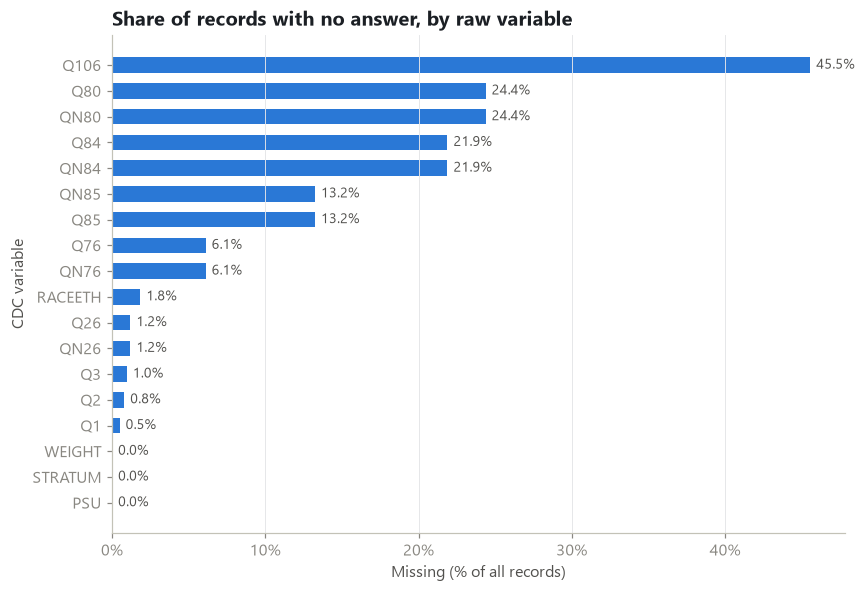

In [7]:
plot_data = (missing.sort_values("missing_percent", ascending=False)
             .reset_index(names="variable").rename(columns={"missing_percent": "percent"}))
fig = pl.hbar_distribution(plot_data, "variable",
                           title="Share of records with no answer, by raw variable",
                           xlabel="Missing (% of all records)", ylabel="CDC variable", figsize=(8, 5.5))
pl.save_fig(fig, "00_missing_values")
plt.show()

**What this chart shows:** the percentage of records where each question was left blank (or could not be read).

**How to read it:** longer bars mean more missing answers. If a variable we rely on has a high missing rate, results for that variable rest on fewer students, and the students who answered may differ from those who did not.

In [8]:
display(Markdown("**Invalid codes (values not in CDC's code list)**"))
display(pd.DataFrame(audit["invalid_codes"]).T)

display(Markdown("**Duplicates**"))
display(pd.Series(audit["duplicates"]).to_frame("value"))

display(Markdown("**Survey weight summary** (outliers are reported, not removed)"))
display(pd.Series(audit["weight"]).to_frame("value"))

display(Markdown("**Our recoding vs CDC's own QN indicators** (agreement should be close to 1.0)"))
display(pd.DataFrame(audit["qn_consistency"]).T)

print("Rows in file:", f"{audit['source_file_rows']:,}",
      "| CDC published N:", f"{audit['published_sample_size']:,}")
print("Warnings:", audit["warnings"] if audit["warnings"] else "none")

**Invalid codes (values not in CDC's code list)**

,count,examples
Q1,0,[]
Q2,0,[]
Q3,0,[]
Q26,0,[]
Q76,0,[]
Q80,0,[]
Q84,0,[]
Q85,0,[]
Q106,0,[]
RACEETH,0,[]


**Duplicates**

,value
exact_full_record_duplicates,0
rows_identical_on_selected_columns,621
note,The file has no respondent ID. Different stude...


**Survey weight summary** (outliers are reported, not removed)

,value
non_numeric,0
non_positive,0
missing,0
min,0.002
median,0.414
max,22.544
mean,1.000
max_to_median_ratio,54.410
iqr_outliers_high,2330
iqr_outliers_low,0


**Our recoding vs CDC's own QN indicators** (agreement should be close to 1.0)

,compared_rows,agreement
QN26,"19,863.000",1.000
QN76,"18,876.000",1.000
QN80,"15,203.000",1.000
QN84,"15,705.000",1.000
QN85,"17,441.000",1.000


Rows in file: 20,103 | CDC published N: 20,103
Warnings: none


**How to read these checks:**
- **Invalid codes** should be 0 or very small. Any that exist are set to missing during cleaning.
- **Exact full-record duplicates** would mean the same line appears twice; those are removed. *Rows identical on selected columns* are **not** removed. The file has no student ID, so two different students giving the same answers is expected.
- **Weights** vary by design. A large max-to-median ratio means a few students represent many others. Weights are kept as they are, because trimming them would change the national estimates.
- **QN agreement** close to 1.0 confirms that our definitions (for example "frequent use = several times a day or more") match CDC's.
- **Row count** is compared with CDC's published sample size. A mismatch would mean the wrong file.

A quick look at the raw answer codes for the social media question:

In [9]:
q80_counts = raw_df["Q80"].value_counts(dropna=False).rename("count").to_frame()
q80_counts["meaning"] = [dp.SOCIAL_MEDIA_LABELS.get(int(c), "INVALID CODE") if str(c).isdigit() else "missing"
                         for c in q80_counts.index]
q80_counts

,count,meaning
Q80,,
6,5888,Several times a day
NaN,4900,missing
8,4803,More than once an hour
7,1181,About once an hour
1,1082,I do not use social media
5,904,About once a day
4,708,A few times a week
2,406,A few times a month
3,231,About once a week


## 9. Data cleaning and preprocessing

`dp.process()` runs the audit and `dp.clean_data()`. These are the same steps `python -m src.data_processing` and the dashboard use. The cleaning steps are:
1. **Invalid codes → missing.**
2. **Drop exact duplicate records.**
3. **Drop rows without a valid survey weight.** They cannot contribute to national estimates.
4. **Recode** CDC codes into readable labels (`social_media_freq`), ordered numeric codes (`social_media_code`) and 0/1 indicators (`social_media_frequent`).
5. **Drop rows that answered none of the study questions.**

**Missing answers are not filled in (no imputation).** Filling in a student's answer would invent a response that was never given. Each analysis uses the students who answered the questions it needs; this is called *available-case analysis*. The sample size `n` is reported for every result so this stays visible.

In [10]:
clean_df, quality_report = dp.process(raw_df)
display(pd.DataFrame(quality_report["cleaning_steps"]))

dp.save_outputs(clean_df, quality_report)   # cleaned_data.csv, data_dictionary.csv, data_quality_report.json

df = dp.load_cleaned_data()                 # reload with proper data types (same loader as the dashboard)
print(f"Cleaned dataset: {df.shape[0]:,} rows x {df.shape[1]} columns")
df.head()

,step,rows,values_changed,rows_removed
0,start,20103,NaN,NaN
1,set invalid answer codes to missing,20103,0.000,NaN
2,drop exact duplicate full records,20103,NaN,0.000
3,drop rows with missing or non-positive survey ...,20103,NaN,0.000
4,recode CDC answer codes to labelled columns,20103,NaN,NaN
5,drop rows with no answer to any study question,20078,NaN,25.000
6,missing answers left as missing (no imputation),20078,NaN,NaN


Cleaned dataset: 20,078 rows x 25 columns


,row_id,age_code,age_label,age_group,sex,grade_code,grade_label,race_ethnicity,social_media_code,social_media_freq,social_media_frequent,sleep_code,sleep_hours_cat,sleep_hours_approx,sleep_8plus,active_days,active_5plus,poor_mh_code,poor_mh_frequency,poor_mental_health,sad_hopeless,difficulty_concentrating,weight,stratum,psu
0,1,3,14 years old,14 or younger,Female,1,9th grade,NaN,6,Several times a day,1,3,6 hours,6,0,0,0,1,Never,0,1,0,0.861,103,16294
1,2,4,15 years old,15,Male,1,9th grade,White,4,A few times a week,0,5,8 hours,8,1,4,0,3,Sometimes,0,0,1,0.892,103,16294
2,3,5,16 years old,16,Male,3,11th grade,White,8,More than once an hour,1,1,4 or less hours,4,0,7,1,2,Rarely,0,1,0,0.508,103,16294
3,4,6,17 years old,17,Female,2,10th grade,White,8,More than once an hour,1,4,7 hours,7,0,2,0,3,Sometimes,0,1,1,1.176,103,16294
4,5,3,14 years old,14 or younger,Male,1,9th grade,White,6,Several times a day,1,3,6 hours,6,0,7,1,3,Sometimes,0,1,0,0.892,103,16294


In [11]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20078 entries, 0 to 20077
Data columns (total 25 columns):
 #   Column                    Non-Null Count  Dtype   
---  ------                    --------------  -----   
 0   row_id                    20078 non-null  Int64   
 1   age_code                  19982 non-null  Int64   
 2   age_label                 19982 non-null  category
 3   age_group                 19982 non-null  category
 4   sex                       19922 non-null  category
 5   grade_code                19888 non-null  Int64   
 6   grade_label               19888 non-null  category
 7   race_ethnicity            19709 non-null  category
 8   social_media_code         15203 non-null  Int64   
 9   social_media_freq         15203 non-null  category
 10  social_media_frequent     15203 non-null  Int8    
 11  sleep_code                17441 non-null  Int64   
 12  sleep_hours_cat           17441 non-null  category
 13  sleep_hours_approx        17441 non-null  Int64   
 14  s

**Data types after cleaning:**
- `category` columns hold labels in their natural order (for example "Never" < "Rarely" < … < "Always"), so charts and sorting follow that order.
- `Int64` / `Int8` are integer columns that can also hold missing values (`<NA>`).
- `weight` is a decimal number.

Next, the project module reports which analyses this dataset can support. Unsupported analyses are **skipped** in the rest of the notebook.

In [12]:
availability = dp.analysis_availability(df)
SUPPORTED = set(availability.loc[availability["available"], "analysis"])
availability

,analysis,available,reason
0,social_media_distribution,True,
1,screen_time_analysis,False,Screen time is not in the 2023 national YRBS.
2,social_media_vs_sleep_duration,True,
3,nighttime_use_vs_sleep_quality,False,Neither nighttime use nor sleep quality is mea...
4,physical_activity_vs_wellbeing,True,
5,social_media_by_age_group,True,
6,social_media_vs_anxiety,False,No anxiety item; use 'social_media_vs_mental_h...
7,social_media_vs_mental_health,True,
8,correlation_matrix,True,


## 10. Descriptive statistics

### 10.1 Sample composition
The **percent** column is the weighted estimate of the share of all US high-school students. **n** is the number of students in the sample.

In [13]:
for col in ["sex", "age_group", "grade_label", "race_ethnicity"]:
    display(Markdown(f"**{col}**  (missing: {df[col].isna().sum():,})"))
    display(au.weighted_distribution(df, col, "weight"))

**sex**  (missing: 156)

,sex,percent,n
0,Female,48.196,9881
1,Male,51.804,10041


**age_group**  (missing: 96)

,age_group,percent,n
0,14 or younger,12.619,2642
1,15,25.261,5518
2,16,25.986,5203
3,17,24.428,4456
4,18 or older,11.705,2163


**grade_label**  (missing: 190)

,grade_label,percent,n
0,9th grade,26.443,5670
1,10th grade,25.758,5407
2,11th grade,24.241,4807
3,12th grade,23.319,3956
4,Ungraded or other grade,0.239,48


**race_ethnicity**  (missing: 369)

,race_ethnicity,percent,n
0,Am Indian/Alaska Native,0.346,1332
1,Asian,4.301,995
2,Black or African American,13.230,1784
3,Native Hawaiian/Other PI,0.372,105
4,White,48.178,9692
5,Hispanic/Latino,7.669,1205
6,Multiple - Hispanic,19.767,2783
7,Multiple - Non-Hispanic,6.138,1813


### 10.2 Study variables

In [14]:
for col in ["social_media_freq", "sleep_hours_cat", "poor_mh_frequency"]:
    display(Markdown(f"**{col}**  (missing: {df[col].isna().sum():,} of {len(df):,})"))
    display(au.weighted_distribution(df, col, "weight"))

**social_media_freq**  (missing: 4,875 of 20,078)

,social_media_freq,percent,n
0,I do not use social media,7.611,1082
1,A few times a month,2.872,406
2,About once a week,1.648,231
3,A few times a week,4.847,708
4,About once a day,6.051,904
5,Several times a day,40.055,5888
6,About once an hour,7.398,1181
7,More than once an hour,29.518,4803


**sleep_hours_cat**  (missing: 2,637 of 20,078)

,sleep_hours_cat,percent,n
0,4 or less hours,8.773,1666
1,5 hours,14.407,2562
2,6 hours,24.989,4342
3,7 hours,28.632,4865
4,8 hours,17.601,3009
5,9 hours,4.076,733
6,10 or more hours,1.521,264


**poor_mh_frequency**  (missing: 4,373 of 20,078)

,poor_mh_frequency,percent,n
0,Never,18.912,2838
1,Rarely,21.622,3308
2,Sometimes,30.929,4751
3,Most of the time,20.292,3377
4,Always,8.246,1431


In [15]:
numeric_cols = ["age_code", "social_media_code", "sleep_hours_approx", "active_days", "poor_mh_code"]
summary = df[numeric_cols].astype(float).describe().T
summary["weighted_mean"] = [au.weighted_mean(df[c], df["weight"]) for c in numeric_cols]
summary["missing"] = df[numeric_cols].isna().sum()
summary

,count,mean,std,min,25%,50%,75%,max,weighted_mean,missing
age_code,"19,982.000",4.893,1.218,1.000,4.000,5.000,6.000,7.000,4.966,96
social_media_code,"15,203.000",6.049,1.982,1.000,6.000,6.000,8.000,8.000,5.962,4875
sleep_hours_approx,"17,441.000",6.473,1.377,4.000,6.000,7.000,7.000,10.000,6.502,2637
active_days,"18,876.000",3.978,2.503,0.000,2.000,4.000,7.000,7.000,3.885,1202
poor_mh_code,"15,705.000",2.825,1.218,1.000,2.000,3.000,4.000,5.000,2.773,4373


**How to read this table:** `count` is the number of non-missing answers. `mean` and `50%` (the median) are unweighted; `weighted_mean` is the national estimate.

The coded variables (`social_media_code`, `poor_mh_code`) are **ordered categories**, so their means are only rough summaries. The distributions above are more informative. `sleep_hours_approx` treats "4 or less" as 4 and "10 or more" as 10.

In [16]:
flags = {
    "social_media_frequent": "Uses social media several times a day or more",
    "sleep_8plus": "Sleeps 8+ hours on school nights",
    "active_5plus": "Physically active 60+ min on 5+ days",
    "poor_mental_health": "Mental health not good most of the time / always",
    "sad_hopeless": "Persistent sadness or hopelessness (past 12 months)",
    "difficulty_concentrating": "Difficulty concentrating (Q106)",
}
key_indicators = pd.DataFrame(
    [dict(zip(["weighted_percent", "ci_low", "ci_high", "n"], au.weighted_share(df[c], df["weight"])),
          indicator=label, column=c) for c, label in flags.items()]
).set_index("indicator")
key_indicators

,weighted_percent,ci_low,ci_high,n,column
indicator,,,,,
Uses social media several times a day or more,76.970,75.901,78.040,15203,social_media_frequent
Sleeps 8+ hours on school nights,23.199,22.200,24.198,17441,sleep_8plus
Physically active 60+ min on 5+ days,46.316,45.161,47.472,18876,active_5plus
Mental health not good most of the time / always,28.537,27.458,29.617,15705,poor_mental_health
Persistent sadness or hopelessness (past 12 months),39.721,38.620,40.823,19863,sad_hopeless
Difficulty concentrating (Q106),45.041,43.695,46.388,10946,difficulty_concentrating


These are the headline national estimates, computed from the data. The 95% CI is approximate (see Section 6).

## 11. Exploratory Data Analysis

EDA looks at the data from several angles before formal testing. Here we break the main indicators down by sex and grade, and check whether **missing answers** are spread evenly across groups. Uneven missingness could bias the results.

In [17]:
eda_rows = []
for group in ["sex", "grade_label"]:
    for flag in ["social_media_frequent", "sleep_8plus", "poor_mental_health", "sad_hopeless"]:
        t = au.weighted_share_by(df, group, flag, "weight").rename(columns={group: "group"})
        t["group"] = t["group"].astype(str)
        t.insert(0, "indicator", flag)
        t.insert(0, "breakdown", group)
        eda_rows.append(t)
eda_table = pd.concat(eda_rows, ignore_index=True)
eda_table.pivot_table(index=["breakdown", "group"], columns="indicator", values="percent")

indicator                            poor_mental_health  sad_hopeless  \
breakdown   group                                                       
grade_label 10th grade                           29.429        39.710   
            11th grade                           29.688        39.718   
            12th grade                           27.886        38.790   
            9th grade                            27.095        40.270   
            Ungraded or other grade              45.113        59.365   
sex         Female                               38.764        52.584   
            Male                                 18.828        27.688   

indicator                            sleep_8plus  social_media_frequent  
breakdown   group                                                        
grade_label 10th grade                    22.029                 78.472  
            11th grade                    20.759                 77.499  
            12th grade                    18.087                 78.185  
            9th grade                     30.990                 74.343  
            Ungraded or other grade       26.324                 42.929  
sex         Female                        21.703                 81.768  
            Male                          24.565                 72.882

**How to read it:** each cell is the weighted % of students in that group who have the indicator. Compare across rows to see which groups differ. These are descriptive differences only; nothing here adjusts for other factors.

In [18]:
missing_by_age = (df.assign(sm_missing=df["social_media_code"].isna(),
                            sleep_missing=df["sleep_code"].isna(),
                            mh_missing=df["poor_mh_code"].isna())
                    .groupby("age_group", observed=True)[["sm_missing", "sleep_missing", "mh_missing"]]
                    .mean() * 100)
missing_by_age.columns = ["% missing social media", "% missing sleep", "% missing mental health"]
missing_by_age

,% missing social media,% missing sleep,% missing mental health
age_group,,,
14 or younger,30.431,14.383,25.927
15,24.030,13.809,25.825
16,25.908,12.858,19.489
17,21.656,11.580,18.582
18 or older,16.921,13.037,18.447


**Why check this?** If, say, younger students skipped the social media question much more often, comparisons by age would rest on different kinds of respondents. Large differences between rows should be mentioned as a limitation.

## 12. Data visualization

Each requested chart is listed below. Where the dataset cannot support a chart, the cell prints the reason and **no chart is produced**; nothing is invented. Where a close substitute exists, it is clearly labelled. The chart functions come from `src/plotting.py`; each cell shows which data goes into the chart.

### Chart 1: Distribution of daily screen time

In [19]:
if "screen_time_analysis" in SUPPORTED:
    raise RuntimeError("Unexpected: screen time is not part of the 2023 YRBS extract.")
print("SKIPPED -", dp.ANALYSES["screen_time_analysis"]["reason"])
print("Substitute below: distribution of social media use FREQUENCY (Chart 1b).")

SKIPPED - Screen time is not in the 2023 national YRBS.
Substitute below: distribution of social media use FREQUENCY (Chart 1b).


### Chart 1b (substitute): How often students use social media

**What it measures:** the weighted percentage of US high-school students in each of the 8 frequency categories of question Q80. This measures how *often* students use social media, **not** how many hours.

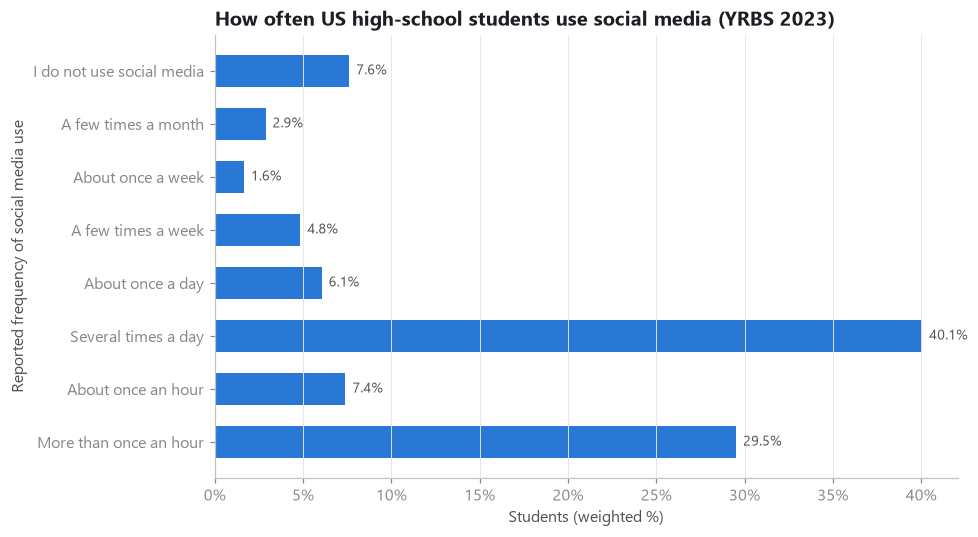

Based on n = 15,203 students who answered Q80.


In [20]:
sm_dist = au.weighted_distribution(df, "social_media_freq", "weight")

fig = pl.hbar_distribution(sm_dist, "social_media_freq",
                           title="How often US high-school students use social media (YRBS 2023)",
                           xlabel="Students (weighted %)", ylabel="Reported frequency of social media use")
pl.save_fig(fig, "01_social_media_frequency")
plt.show()
print(f"Based on n = {int(sm_dist['n'].sum()):,} students who answered Q80.")

In [21]:
top = sm_dist.loc[sm_dist["percent"].idxmax()]
median_cat = au.weighted_median_category(df, "social_media_freq", "weight")
frequent_pct = key_indicators.loc["Uses social media several times a day or more", "weighted_percent"]
non_users = sm_dist.loc[sm_dist["social_media_freq"] == "I do not use social media", "percent"].sum()
print(f"Most common answer: '{top['social_media_freq']}' ({top['percent']:.1f}% of students).")
print(f"Weighted median category: '{median_cat}'.")
print(f"Several times a day or more often (combined): {frequent_pct:.1f}%.")
print(f"Do not use social media: {non_users:.1f}%.")

Most common answer: 'Several times a day' (40.1% of students).
Weighted median category: 'Several times a day'.
Several times a day or more often (combined): 77.0%.
Do not use social media: 7.6%.


**How to interpret:** the printed summary above is computed from the chart's data. The *median category* is the answer of the "middle" student once all students are ordered from least to most frequent use. Because the scale is ordered categories, the median is more meaningful here than an average.

### Chart 2: Screen time vs sleep duration

In [22]:
print("SKIPPED - screen time is not measured in the 2023 YRBS.")
print("Substitute below: social media use FREQUENCY vs sleep duration (Charts 2a and 2b).")

SKIPPED - screen time is not measured in the 2023 YRBS.
Substitute below: social media use FREQUENCY vs sleep duration (Charts 2a and 2b).


### Chart 2a (substitute): Share sleeping 8+ hours, by social media frequency

**What it measures:** for each social media frequency level, the weighted % of students who report **8 or more hours** of sleep on an average school night. Error bars are approximate 95% confidence intervals.

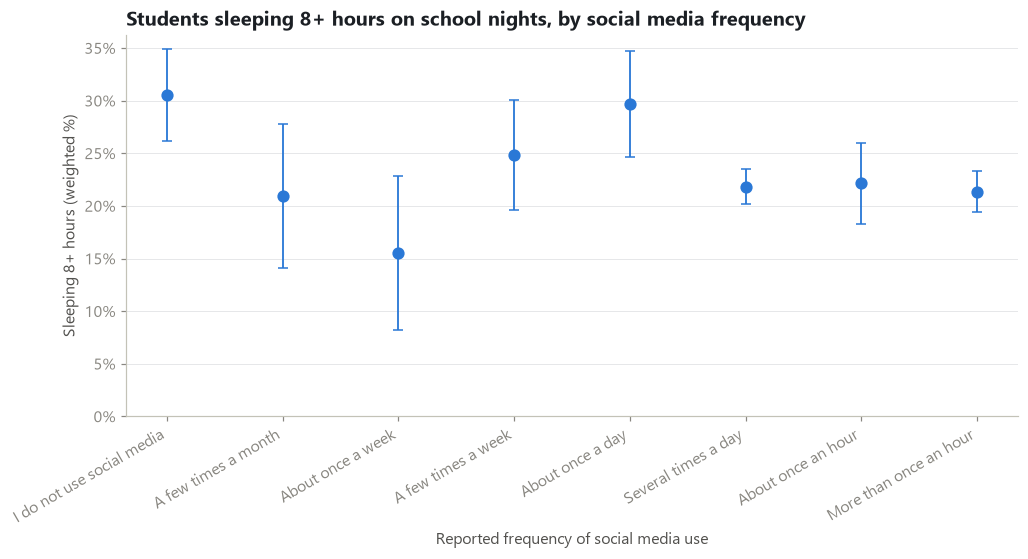

,social_media_freq,percent,ci_low,ci_high,n
0,I do not use social media,30.563,26.206,34.920,925
1,A few times a month,20.953,14.110,27.796,359
2,About once a week,15.498,8.194,22.802,198
3,A few times a week,24.834,19.632,30.035,642
4,About once a day,29.689,24.617,34.761,817
5,Several times a day,21.843,20.142,23.543,5377
6,About once an hour,22.142,18.260,26.023,1044
7,More than once an hour,21.365,19.420,23.310,4368


In [23]:
sleep_by_sm = au.weighted_share_by(df, "social_media_freq", "sleep_8plus", "weight")

fig = pl.share_points([(sleep_by_sm, "Sleeping 8+ hours", pl.BLUE)], "social_media_freq",
                      title="Students sleeping 8+ hours on school nights, by social media frequency",
                      xlabel="Reported frequency of social media use", ylabel="Sleeping 8+ hours (weighted %)")
pl.save_fig(fig, "02a_sleep8_by_social_media")
plt.show()
sleep_by_sm

In [24]:
rho_sm_sleep = au.spearman(df, "social_media_code", "sleep_hours_approx")
lo_row = sleep_by_sm.loc[sleep_by_sm["percent"].idxmin()]
hi_row = sleep_by_sm.loc[sleep_by_sm["percent"].idxmax()]
print(f"Lowest share sleeping 8+ h : '{lo_row['social_media_freq']}' ({lo_row['percent']:.1f}%, n={lo_row['n']:,})")
print(f"Highest share sleeping 8+ h: '{hi_row['social_media_freq']}' ({hi_row['percent']:.1f}%, n={hi_row['n']:,})")
print(f"Spearman rho (frequency vs sleep hours) = {rho_sm_sleep['statistic']:.3f} "
      f"[{rho_sm_sleep['effect']}], n = {rho_sm_sleep['n']:,}, p = {au.format_p(rho_sm_sleep['p_value'])}")
print("Overall pattern:", au.association_phrase(rho_sm_sleep, "More frequent social media use", "sleep hours",
                                                "more sleep", "less sleep"), "This is not proof of cause.")

Lowest share sleeping 8+ h : 'About once a week' (15.5%, n=198)
Highest share sleeping 8+ h: 'I do not use social media' (30.6%, n=925)
Spearman rho (frequency vs sleep hours) = -0.071 [negligible], n = 13,730, p = 5.28e-17
Overall pattern: More frequent social media use shows only a negligible association with sleep hours (Spearman rho = -0.07). This is not proof of cause.


**How to interpret:** compare the dots from left (least frequent use) to right (most frequent use).
- If the dots trend up or down, sleep and social media frequency are associated. The sign of Spearman's ρ printed above gives the overall direction, and the effect label tells how strong the association is. When the effect is *negligible*, the summary says "no meaningful difference" instead of naming a direction.
- Overlapping error bars mean two neighbouring groups may not really differ.
- Small groups have wide intervals.

### Chart 2b (substitute): Full sleep distribution within each social media level

**What it measures:** within each social media frequency level, the weighted share of students in each sleep category. Every bar adds up to 100%.

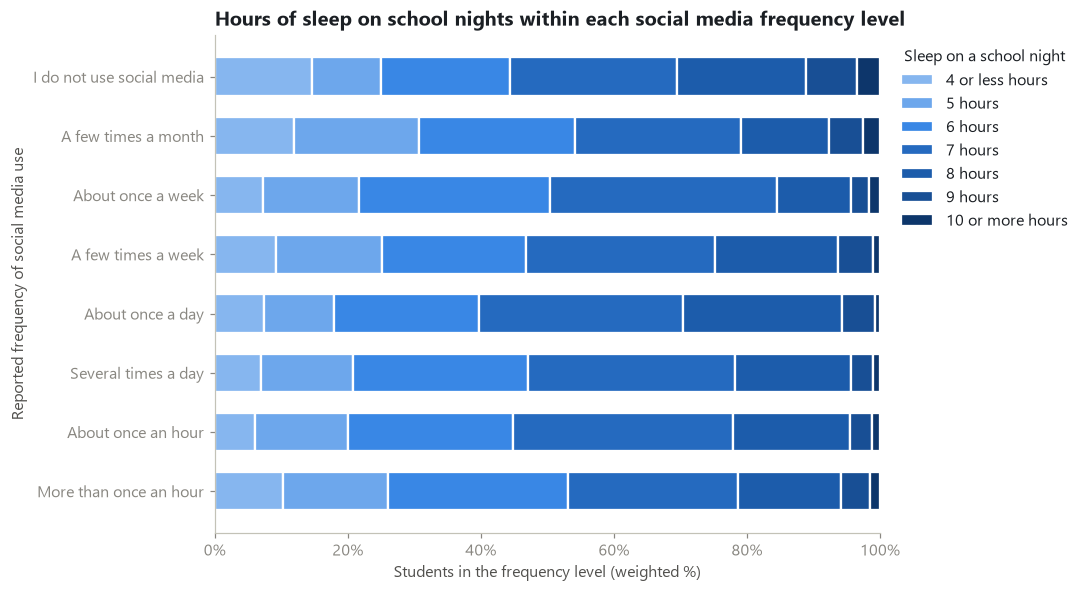

In [25]:
sleep_mix = (au.weighted_crosstab(df, "social_media_freq", "sleep_hours_cat", "weight")
             .pivot_table(index="social_media_freq", columns="sleep_hours_cat", values="percent",
                          observed=True, sort=True))

fig = pl.stacked_100(sleep_mix, title="Hours of sleep on school nights within each social media frequency level",
                     xlabel="Students in the frequency level (weighted %)",
                     ylabel="Reported frequency of social media use", legend_title="Sleep on a school night")
pl.save_fig(fig, "02b_sleep_distribution_by_social_media")
plt.show()

**How to interpret:** light blue means less sleep and dark blue means more. If the dark segments shrink or grow as you move down the bars (towards more frequent use), the sleep distribution differs by social media frequency. The statistical tests for this are in Section 14.

### Chart 3: Nighttime social media use vs sleep quality

In [26]:
if "nighttime_use_vs_sleep_quality" in SUPPORTED:
    raise RuntimeError("Unexpected: nighttime use / sleep quality are not in the 2023 YRBS extract.")
print("SKIPPED -", dp.ANALYSES["nighttime_use_vs_sleep_quality"]["reason"])
print("No substitute is shown: the YRBS has no question about phone use at night or about sleep quality.")

SKIPPED - Neither nighttime use nor sleep quality is measured.
No substitute is shown: the YRBS has no question about phone use at night or about sleep quality.


### Chart 4: Social media use vs self-reported anxiety

In [27]:
print("SKIPPED -", dp.ANALYSES["social_media_vs_anxiety"]["reason"])
print("Substitute below: social media frequency vs poor mental health and persistent sadness (Chart 4b).")
print("These are NOT anxiety measures and are labelled accordingly.")

SKIPPED - No anxiety item; use 'social_media_vs_mental_health' and label it accordingly.
Substitute below: social media frequency vs poor mental health and persistent sadness (Chart 4b).
These are NOT anxiety measures and are labelled accordingly.


### Chart 4b (substitute): Poor mental health and persistent sadness, by social media frequency

**What it measures:** for each social media frequency level, two weighted percentages:
- **blue:** mental health "not good" *most of the time or always* in the past 30 days (Q84)
- **teal:** persistent sadness or hopelessness in the past 12 months (Q26)

Both are percentages, so they share one axis.

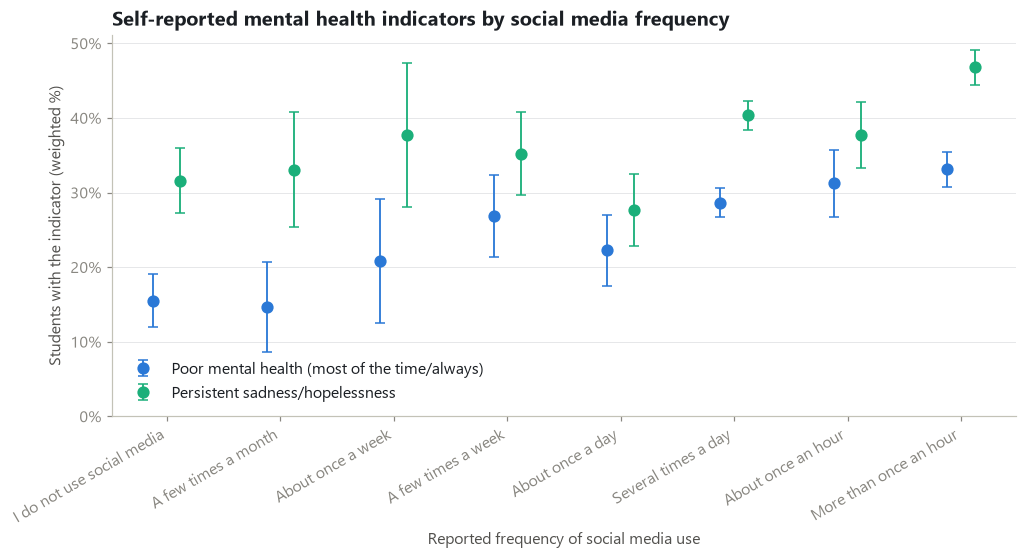

,social_media_freq,percent_poor_mh,ci_low_poor_mh,ci_high_poor_mh,n_poor_mh,percent_sad,ci_low_sad,ci_high_sad,n_sad
0,I do not use social media,15.495,11.959,19.032,784,31.608,27.305,35.912,1060
1,A few times a month,14.651,8.619,20.684,307,33.068,25.377,40.759,396
2,About once a week,20.836,12.528,29.143,175,37.704,28.058,47.349,221
3,A few times a week,26.849,21.349,32.349,537,35.224,29.611,40.838,699
4,About once a day,22.248,17.532,26.965,674,27.700,22.903,32.497,901
5,Several times a day,28.645,26.732,30.557,4587,40.345,38.364,42.326,5858
6,About once an hour,31.240,26.746,35.735,856,37.748,33.319,42.178,1171
7,More than once an hour,33.103,30.794,35.412,3682,46.796,44.474,49.119,4769


In [28]:
mh_by_sm = au.weighted_share_by(df, "social_media_freq", "poor_mental_health", "weight")
sad_by_sm = au.weighted_share_by(df, "social_media_freq", "sad_hopeless", "weight")

fig = pl.share_points([(mh_by_sm, "Poor mental health (most of the time/always)", pl.BLUE),
                       (sad_by_sm, "Persistent sadness/hopelessness", pl.TEAL)], "social_media_freq",
                      title="Self-reported mental health indicators by social media frequency",
                      xlabel="Reported frequency of social media use",
                      ylabel="Students with the indicator (weighted %)")
pl.save_fig(fig, "04b_mental_health_by_social_media")
plt.show()
mh_by_sm.merge(sad_by_sm, on="social_media_freq", suffixes=("_poor_mh", "_sad"))

In [29]:
for name, t, col in [("Poor mental health", mh_by_sm, "poor_mh_code"),
                     ("Persistent sadness", sad_by_sm, "sad_hopeless")]:
    rho = au.spearman(df, "social_media_code", col)
    lo_row, hi_row = t.loc[t["percent"].idxmin()], t.loc[t["percent"].idxmax()]
    print(f"{name}: lowest in '{lo_row['social_media_freq']}' ({lo_row['percent']:.1f}%), "
          f"highest in '{hi_row['social_media_freq']}' ({hi_row['percent']:.1f}%).")
    print(f"   Spearman rho with social media frequency = {rho['statistic']:.3f} [{rho['effect']}], "
          f"n = {rho['n']:,}, p = {au.format_p(rho['p_value'])}")

Poor mental health: lowest in 'A few times a month' (14.7%), highest in 'More than once an hour' (33.1%).
   Spearman rho with social media frequency = 0.141 [small], n = 11,602, p = 1.90e-52
Persistent sadness: lowest in 'About once a day' (27.7%), highest in 'More than once an hour' (46.8%).
   Spearman rho with social media frequency = 0.116 [small], n = 15,075, p = 1.25e-46


**How to interpret:**
- Read each colour from left to right. A rising or falling pattern means the indicator is associated with social media frequency.
- The pattern need not be a straight line. For example, both the lowest and highest frequency groups could differ from the middle.
- Even a clear pattern does **not** show that social media causes poorer mental health. The reverse is possible (students who feel worse may use social media more), and other factors (family, school, sleep) may influence both.

### Chart 5: Physical activity vs self-reported well-being

**What it measures:** for each number of active days (0–7) in the past week, the weighted % of students reporting poor mental health (blue) and persistent sadness (teal).

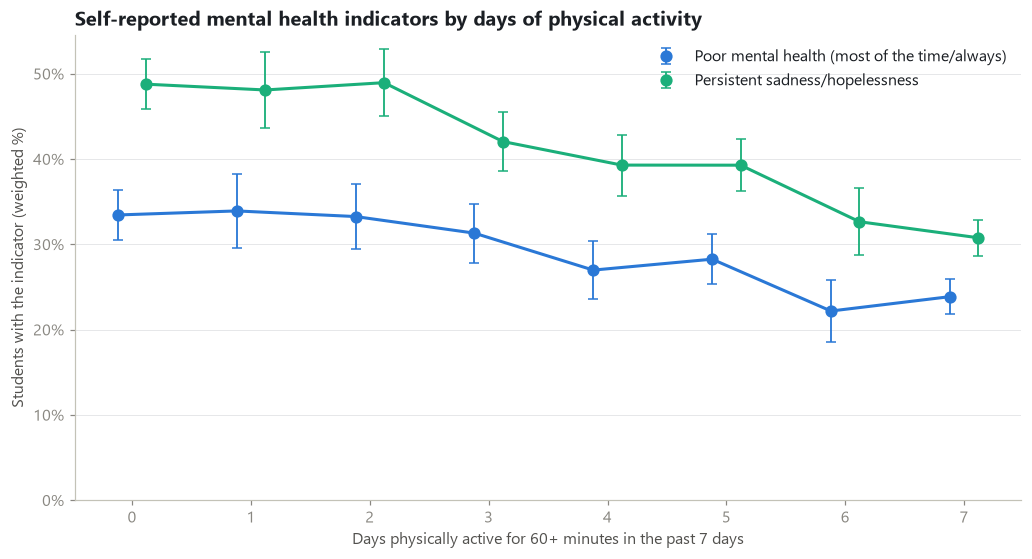

,active_days,percent_poor_mh,ci_low_poor_mh,ci_high_poor_mh,n_poor_mh,percent_sad,ci_low_sad,ci_high_sad,n_sad
0,0,33.436,30.558,36.314,2274,48.768,45.834,51.703,2773
1,1,33.910,29.568,38.251,1076,48.092,43.657,52.527,1291
2,2,33.251,29.403,37.099,1372,48.949,45.055,52.843,1696
3,3,31.306,27.854,34.759,1633,42.044,38.560,45.529,2071
4,4,26.972,23.562,30.382,1476,39.284,35.715,42.853,1867
5,5,28.252,25.342,31.161,2128,39.273,36.257,42.290,2649
6,6,22.174,18.531,25.817,1224,32.643,28.721,36.565,1530
7,7,23.857,21.779,25.936,3927,30.762,28.626,32.898,4815


In [30]:
mh_by_pa = au.weighted_share_by(df, "active_days", "poor_mental_health", "weight")
sad_by_pa = au.weighted_share_by(df, "active_days", "sad_hopeless", "weight")

fig = pl.share_points([(mh_by_pa, "Poor mental health (most of the time/always)", pl.BLUE),
                       (sad_by_pa, "Persistent sadness/hopelessness", pl.TEAL)], "active_days",
                      title="Self-reported mental health indicators by days of physical activity",
                      xlabel="Days physically active for 60+ minutes in the past 7 days",
                      ylabel="Students with the indicator (weighted %)", connect=True, numeric_x=True)
pl.save_fig(fig, "05_mental_health_by_activity")
plt.show()
mh_by_pa.merge(sad_by_pa, on="active_days", suffixes=("_poor_mh", "_sad"))

In [31]:
for name, t, col in [("Poor mental health", mh_by_pa, "poor_mh_code"),
                     ("Persistent sadness", sad_by_pa, "sad_hopeless")]:
    rho = au.spearman(df, "active_days", col)
    first, last = t.iloc[0], t.iloc[-1]
    print(f"{name}: {first['percent']:.1f}% at {int(first['active_days'])} days vs "
          f"{last['percent']:.1f}% at {int(last['active_days'])} days.")
    print(f"   Spearman rho with active days = {rho['statistic']:.3f} [{rho['effect']}], "
          f"n = {rho['n']:,}, p = {au.format_p(rho['p_value'])}")

Poor mental health: 33.4% at 0 days vs 23.9% at 7 days.
   Spearman rho with active days = -0.119 [small], n = 15,110, p = 9.55e-49
Persistent sadness: 48.8% at 0 days vs 30.8% at 7 days.
   Spearman rho with active days = -0.135 [small], n = 18,692, p = 3.33e-77


**How to interpret:** a downward slope would mean more active students less often report the indicator; an upward slope the opposite. The sign of ρ printed above summarises the overall direction.

Again this is an association. Being active might support mental health, poor mental health might make it harder to be active, or other factors may drive both.

### Chart 6: Average social media usage across age groups

Social media use is measured in ordered categories, so a true "average" (mean) is not meaningful. We show the **share of frequent users** (several times a day or more) per age group, and the table below the chart gives each group's **median category**.

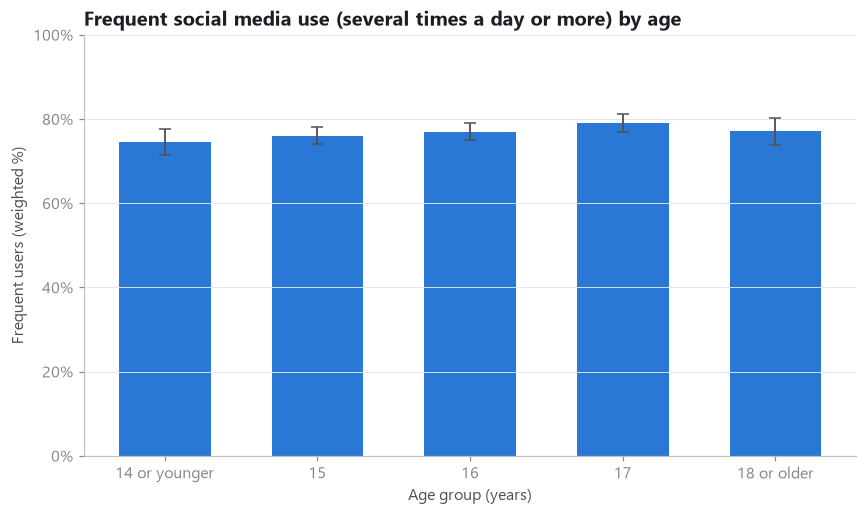

,age_group,percent,ci_low,ci_high,n,median_category
0,14 or younger,74.507,71.365,77.650,1838,Several times a day
1,15,76.053,74.011,78.095,4192,Several times a day
2,16,77.001,74.933,79.070,3855,Several times a day
3,17,79.054,76.879,81.230,3491,Several times a day
4,18 or older,77.070,73.800,80.340,1797,Several times a day


In [32]:
freq_by_age = au.weighted_share_by(df, "age_group", "social_media_frequent", "weight")

fig = pl.bar_with_ci(freq_by_age, "age_group",
                     title="Frequent social media use (several times a day or more) by age",
                     xlabel="Age group (years)", ylabel="Frequent users (weighted %)", ylim=(0, 100))
pl.save_fig(fig, "06_frequent_use_by_age")
plt.show()

freq_by_age["median_category"] = [au.weighted_median_category(df[df["age_group"] == g], "social_media_freq", "weight")
                                  for g in freq_by_age["age_group"]]
freq_by_age

In [33]:
rho_age = au.spearman(df, "age_code", "social_media_code")
lo_row, hi_row = freq_by_age.loc[freq_by_age["percent"].idxmin()], freq_by_age.loc[freq_by_age["percent"].idxmax()]
print(f"Lowest share of frequent users : age {lo_row['age_group']} ({lo_row['percent']:.1f}%, n={lo_row['n']:,})")
print(f"Highest share of frequent users: age {hi_row['age_group']} ({hi_row['percent']:.1f}%, n={hi_row['n']:,})")
print(f"Spearman rho (age vs frequency) = {rho_age['statistic']:.3f} [{rho_age['effect']}], "
      f"n = {rho_age['n']:,}, p = {au.format_p(rho_age['p_value'])}")

Lowest share of frequent users : age 14 or younger (74.5%, n=1,838)
Highest share of frequent users: age 17 (79.1%, n=3,491)
Spearman rho (age vs frequency) = 0.024 [negligible], n = 15,173, p = 0.0029


**How to interpret:** compare bar heights across age groups. Overlapping error bars suggest the groups may not truly differ. The age range is narrow (high school only), so this compares younger and older *teenagers*, not age groups across life.

### Chart 7: Sleep duration in frequent vs less frequent social media users

**What it measures:** the weighted % of students in each sleep category, compared between frequent users (several times a day or more) and everyone else who answered Q80, including non-users.

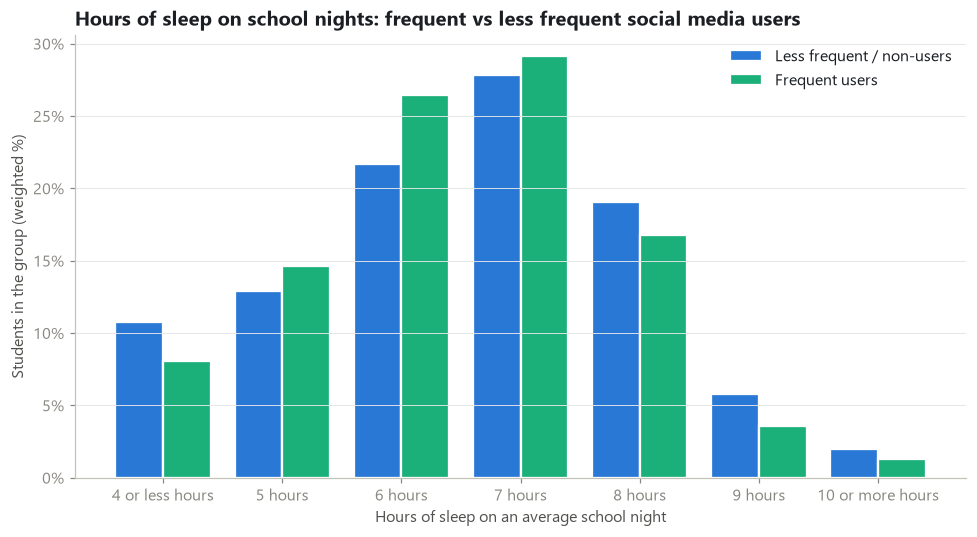

usage_group,Less frequent / non-users,Frequent users
sleep_hours_cat,,
4 or less hours,10.750,8.091
5 hours,12.889,14.627
6 hours,21.671,26.436
7 hours,27.812,29.158
8 hours,19.070,16.792
9 hours,5.788,3.614
10 or more hours,2.021,1.283


In [34]:
usage_group = df["social_media_frequent"].map({1: "Frequent users", 0: "Less frequent / non-users"})
sleep_by_group = (au.weighted_crosstab(df.assign(usage_group=usage_group), "usage_group", "sleep_hours_cat", "weight")
                  .pivot_table(index="sleep_hours_cat", columns="usage_group", values="percent", observed=True))
sleep_by_group = sleep_by_group[["Less frequent / non-users", "Frequent users"]]

fig = pl.grouped_bars(sleep_by_group,
                      title="Hours of sleep on school nights: frequent vs less frequent social media users",
                      xlabel="Hours of sleep on an average school night",
                      ylabel="Students in the group (weighted %)")
pl.save_fig(fig, "07_sleep_by_usage_group")
plt.show()
sleep_by_group

In [35]:
for label, value in [("Frequent users", 1), ("Less frequent / non-users", 0)]:
    sub = df[au.is_level(df["social_media_frequent"], value)]
    print(f"{label}: weighted mean sleep = {au.weighted_mean(sub['sleep_hours_approx'], sub['weight']):.2f} h "
          f"(approx.), weighted % sleeping 8+ h = {au.weighted_share(sub['sleep_8plus'], sub['weight'])[0]:.1f}%, "
          f"n = {sub['sleep_hours_approx'].notna().sum():,}")

Frequent users: weighted mean sleep = 6.48 h (approx.), weighted % sleeping 8+ h = 21.7%, n = 10,789
Less frequent / non-users: weighted mean sleep = 6.57 h (approx.), weighted % sleeping 8+ h = 26.9%, n = 2,941


**How to interpret:** if the teal bars are taller on the short-sleep side and the blue bars on the long-sleep side, frequent users tend to sleep less, and vice versa. The printed means are approximate, because "4 or less" and "10 or more" are counted as 4 and 10. The formal comparison (Mann–Whitney U) is in Section 14.

## 13. Correlation analysis

### Chart 8: Correlation heatmap

We compute **Spearman** correlations between all pairs of study variables. Each pair uses the students who answered both questions (*pairwise* deletion), so `n` differs between pairs. The dashboard draws the same heatmap with the same function.

How to read the variables:
- higher `social_media_code` = more frequent use
- higher `sleep_hours_approx` = more sleep
- higher `active_days` = more activity
- higher `poor_mh_code` = mental health not good **more often** (worse)
- `sad_hopeless` and `difficulty_concentrating` are 1 = yes

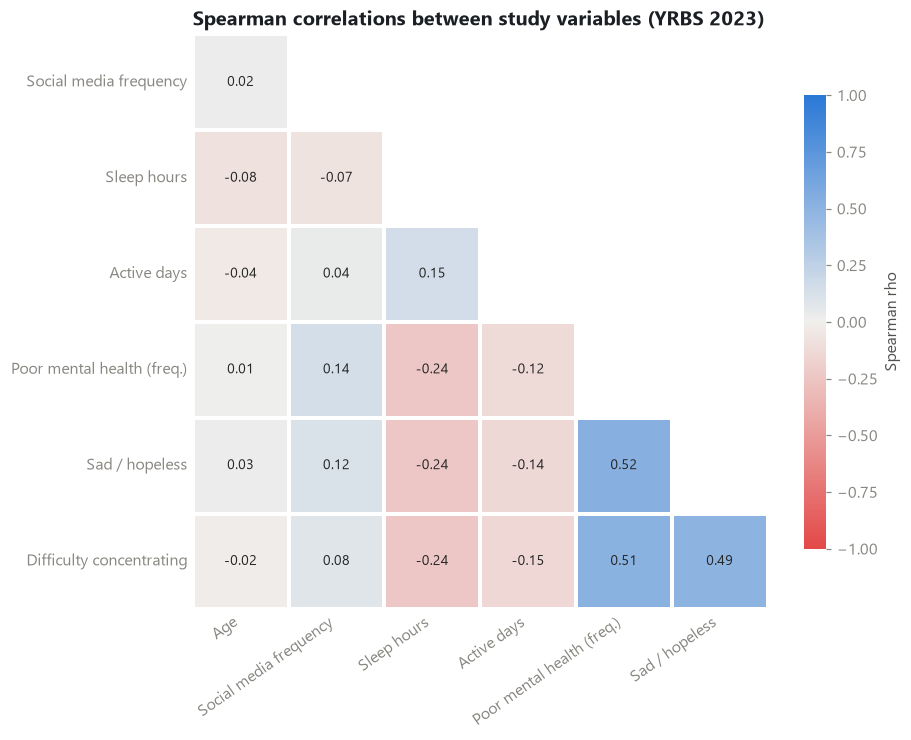

In [36]:
spearman_matrix = au.spearman_matrix(df, au.CORRELATION_VARIABLES)
fig = pl.correlation_heatmap(spearman_matrix, title="Spearman correlations between study variables (YRBS 2023)")
pl.save_fig(fig, "08_spearman_heatmap")
plt.show()

**What it measures:** each cell is Spearman's ρ for one pair of variables. **Blue** means positive (they rise together), **red** means negative (one rises as the other falls), and **grey** means close to zero.

**How to interpret:** look at the colour and the number.
- |ρ| < 0.1 is negligible, 0.1–0.3 small, 0.3–0.5 moderate, and above 0.5 large. These are rough guides.
- Correlations between the three mental-health measures are expected, because they describe related experiences.
- The table below lists every pair with its sample size and p-value.
- Correlation is not causation, and Spearman only captures relationships that consistently go one way (*monotonic* relationships).

In [37]:
cols = list(au.CORRELATION_VARIABLES)
pairs = [au.spearman(df, a, b) for i, a in enumerate(cols) for b in cols[i + 1:]]
correlation_table = (pd.DataFrame(pairs)[["x", "y", "n", "statistic", "p_value", "effect"]]
                     .rename(columns={"statistic": "spearman_rho"})
                     .assign(abs_rho=lambda t: t["spearman_rho"].abs())
                     .sort_values("abs_rho", ascending=False)
                     .drop(columns="abs_rho")
                     .reset_index(drop=True))
correlation_table["p_value"] = correlation_table["p_value"].map(au.format_p)
correlation_table

,x,y,n,spearman_rho,p_value,effect
0,poor_mh_code,sad_hopeless,15542,0.524,< 1e-300,large
1,poor_mh_code,difficulty_concentrating,10769,0.512,< 1e-300,large
2,sad_hopeless,difficulty_concentrating,10879,0.493,< 1e-300,moderate
3,sleep_hours_approx,difficulty_concentrating,10787,-0.240,3.59e-141,small
4,sleep_hours_approx,sad_hopeless,17266,-0.239,7.92e-223,small
5,sleep_hours_approx,poor_mh_code,14790,-0.238,8.41e-190,small
6,sleep_hours_approx,active_days,17215,0.149,1.24e-85,small
7,active_days,difficulty_concentrating,10790,-0.146,1.40e-52,small
8,social_media_code,poor_mh_code,11602,0.141,1.90e-52,small
9,active_days,sad_hopeless,18692,-0.135,3.33e-77,small


**Why Spearman and not Pearson?** Pearson's r assumes both variables are measured on an evenly spaced numeric scale and related in a straight line. Here most variables are ordered categories ("Never … Always", or frequency levels), where the gap between "About once a day" and "Several times a day" is not a fixed amount. Spearman only uses the *order* of the values, which suits this data.

## 14. Statistical hypothesis testing

For every test we state the null hypothesis (H0), the alternative hypothesis (H1), the sample size, the test statistic, the p-value and an effect size. Every alternative is **two-sided**: we test for a difference or association in *either* direction.

The significance level is α = 0.05. Because several tests are run, Section 14.9 also applies the **Holm correction** for multiple testing.

**Important assumption:** these classical tests treat students as independent observations and ignore the survey weights and clustering. That makes the p-values somewhat too small. The weighted, cluster-adjusted regression in 14.8 addresses this partly.

### 14.1 Social media frequency and poor mental health (chi-square)

In [38]:
t1 = au.chi_square(df, "social_media_frequent", "poor_mental_health")
print(au.describe_test(t1,
      h0="Frequent social media use and poor mental health are independent.",
      h1="Frequent social media use and poor mental health are associated."))
t1["table"]

Chi-square: social_media_frequent  vs  poor_mental_health
  H0: Frequent social media use and poor mental health are independent.
  H1: Frequent social media use and poor mental health are associated.
  Sample size (n): 11,602
  Test statistic chi2 (df=1): 94.1568
  p-value: 2.91e-22
  Effect size (Cramer's V): 0.0901  [negligible]
  Smallest expected cell count: 753.0 (OK)
  Decision at alpha = 0.05: reject H0


poor_mental_health,0,1
social_media_frequent,,
0,1921,556
1,6154,2971


### 14.2 Social media frequency and persistent sadness (chi-square)

In [39]:
t2 = au.chi_square(df, "social_media_frequent", "sad_hopeless")
print(au.describe_test(t2,
      h0="Frequent social media use and persistent sadness are independent.",
      h1="Frequent social media use and persistent sadness are associated."))
t2["table"]

Chi-square: social_media_frequent  vs  sad_hopeless
  H0: Frequent social media use and persistent sadness are independent.
  H1: Frequent social media use and persistent sadness are associated.
  Sample size (n): 15,075
  Test statistic chi2 (df=1): 125.5390
  p-value: 3.88e-29
  Effect size (Cramer's V): 0.0913  [negligible]
  Smallest expected cell count: 1,368.8 (OK)
  Decision at alpha = 0.05: reject H0


sad_hopeless,0,1
social_media_frequent,,
0,2188,1089
1,6590,5208


### 14.3 Sleep hours: frequent vs less frequent users (Mann–Whitney U)

The rank-biserial *r* is positive if frequent users tend to report **more** sleep, and negative if they tend to report **less**.

In [40]:
t3 = au.mann_whitney(df, "sleep_hours_approx", "social_media_frequent", 1, 0)
print(au.describe_test(t3,
      h0="Sleep-hour distributions are the same for frequent and less frequent users.",
      h1="Sleep-hour distributions differ between frequent and less frequent users."))
print(f"  Frequent users      : n = {t3['n_a']:,}, median = {t3['median_a']:.0f} h, mean = {t3['mean_a']:.2f} h")
print(f"  Less frequent users : n = {t3['n_b']:,}, median = {t3['median_b']:.0f} h, mean = {t3['mean_b']:.2f} h")

Mann-Whitney U: social_media_frequent (1 vs 0)  vs  sleep_hours_approx
  H0: Sleep-hour distributions are the same for frequent and less frequent users.
  H1: Sleep-hour distributions differ between frequent and less frequent users.
  Sample size (n): 13,730
  Test statistic U: 14,836,555.5000
  p-value: 3.26e-08
  Effect size (rank-biserial r): -0.0648  [negligible]
  Decision at alpha = 0.05: reject H0
  Frequent users      : n = 10,789, median = 6 h, mean = 6.42 h
  Less frequent users : n = 2,941, median = 7 h, mean = 6.58 h


### 14.4 Sleep hours across all 8 social media levels (Kruskal–Wallis)

Effect size ε² is the share of variation in sleep ranks explained by the group. Values near 0.01 are often called small, 0.06 medium and 0.14 large.

In [41]:
t4 = au.kruskal(df, "sleep_hours_approx", "social_media_freq")
print(au.describe_test(t4,
      h0="Sleep-hour distributions are the same in all social media frequency levels.",
      h1="At least one social media frequency level has a different sleep-hour distribution."))

Kruskal-Wallis: social_media_freq  vs  sleep_hours_approx
  H0: Sleep-hour distributions are the same in all social media frequency levels.
  H1: At least one social media frequency level has a different sleep-hour distribution.
  Sample size (n): 13,730
  Test statistic H (groups=8): 98.7611
  p-value: 1.94e-18
  Effect size (epsilon-squared): 0.0067  [negligible]
  Decision at alpha = 0.05: reject H0


### 14.5 Physical activity and poor mental health (Spearman)

In [42]:
t5 = au.spearman(df, "active_days", "poor_mh_code")
print(au.describe_test(t5,
      h0="There is no monotonic association between active days and poor-mental-health frequency (rho = 0).",
      h1="There is a monotonic association (rho != 0)."))

Spearman: active_days  vs  poor_mh_code
  H0: There is no monotonic association between active days and poor-mental-health frequency (rho = 0).
  H1: There is a monotonic association (rho != 0).
  Sample size (n): 15,110
  Test statistic rho: -0.1190
  p-value: 9.55e-49
  Effect size (Spearman rho): -0.1190  [small]
  Decision at alpha = 0.05: reject H0


### 14.6 Physical activity (5+ days) and poor mental health (chi-square)

In [43]:
t6 = au.chi_square(df, "active_5plus", "poor_mental_health")
print(au.describe_test(t6,
      h0="Being active 5+ days and poor mental health are independent.",
      h1="Being active 5+ days and poor mental health are associated."))
t6["table"]

Chi-square: active_5plus  vs  poor_mental_health
  H0: Being active 5+ days and poor mental health are independent.
  H1: Being active 5+ days and poor mental health are associated.
  Sample size (n): 15,110
  Test statistic chi2 (df=1): 117.3766
  p-value: 2.37e-27
  Effect size (Cramer's V): 0.0881  [negligible]
  Smallest expected cell count: 2,239.1 (OK)
  Decision at alpha = 0.05: reject H0


poor_mental_health,0,1
active_5plus,,
0,5115,2716
1,5347,1932


### 14.7 Age group and frequent social media use (chi-square)

In [44]:
t7 = au.chi_square(df, "age_group", "social_media_frequent")
print(au.describe_test(t7,
      h0="Frequent social media use is independent of age group.",
      h1="Frequent social media use differs by age group."))
t7["table"]

Chi-square: age_group  vs  social_media_frequent
  H0: Frequent social media use is independent of age group.
  H1: Frequent social media use differs by age group.
  Sample size (n): 15,173
  Test statistic chi2 (df=4): 20.6118
  p-value: 3.78e-04
  Effect size (Cramer's V): 0.0369  [negligible]
  Smallest expected cell count: 393.2 (OK)
  Decision at alpha = 0.05: reject H0


social_media_frequent,0,1
age_group,,
14 or younger,457,1381
15,958,3234
16,815,3040
17,697,2794
18 or older,393,1404


### 14.8 Adjusted association: weighted logistic regression

The tests above look at two variables at a time. Here we look at several together. The model estimates the **odds** of poor mental health (most of the time or always) for each factor, *holding the others constant*. The factors are frequent social media use, 8+ hours of sleep, being active 5+ days, sex, age group and race/ethnicity.

- **Weights:** the survey weights are used (scaled so they average 1).
- **Standard errors:** clustered by primary sampling unit (PSU), to respect the survey design. Strata are not modelled, so this approximates a full survey analysis.
- **Odds ratio (OR):**
  - OR > 1 means higher odds of poor mental health
  - OR < 1 means lower odds
  - OR = 1 means no association
  - If the 95% CI includes 1, the data are consistent with no association.
- Only students with no missing value in any model variable are used (*complete cases*).

In [45]:
model_cols = ["poor_mental_health", "social_media_frequent", "sleep_8plus", "active_5plus",
              "sex", "age_group", "race_ethnicity", "weight", "stratum", "psu"]
md = df[model_cols].dropna().copy()
for c in ["poor_mental_health", "social_media_frequent", "sleep_8plus", "active_5plus"]:
    md[c] = md[c].astype(int)
for c in ["sex", "age_group", "race_ethnicity"]:
    md[c] = md[c].astype(str)                       # plain text avoids empty categories in the model
md["w"] = md["weight"] / md["weight"].mean()        # scale weights to mean 1
md["cluster"] = pd.factorize(md["stratum"].astype(str) + "_" + md["psu"].astype(str))[0]

# Reference groups: the largest age group and race/ethnicity group in this sample
age_ref = md["age_group"].value_counts().idxmax()
race_ref = md["race_ethnicity"].value_counts().idxmax()
formula = ("poor_mental_health ~ social_media_frequent + sleep_8plus + active_5plus + C(sex)"
           f" + C(age_group, Treatment('{age_ref}')) + C(race_ethnicity, Treatment('{race_ref}'))")
with warnings.catch_warnings():
    # statsmodels prints a generic "cov_type not fully supported with var_weights" caution here. The project's
    # tests (tests/test_regression_se.py) recompute the cluster-robust standard errors by hand and they match,
    # so the caution does not apply to this binomial model and is hidden to keep the output readable.
    warnings.filterwarnings("ignore", message="cov_type not fully supported with var_weights")
    logit = smf.glm(formula, data=md, family=sm.families.Binomial(), var_weights=md["w"]).fit(
        cov_type="cluster", cov_kwds={"groups": md["cluster"]})

ci = logit.conf_int()
odds = pd.DataFrame({"odds_ratio": np.exp(logit.params), "ci_low": np.exp(ci[0]),
                     "ci_high": np.exp(ci[1]), "p_value": logit.pvalues}).drop(index="Intercept")
print(f"Complete cases used: n = {len(md):,} of {len(df):,} students; clusters = {md['cluster'].nunique()}")
print(f"Reference groups: age {age_ref}, race/ethnicity '{race_ref}', sex 'Female'.")
odds.assign(p_value=odds["p_value"].map(au.format_p))

Complete cases used: n = 10,941 of 20,078 students; clusters = 75
Reference groups: age 16, race/ethnicity 'White', sex 'Female'.


,odds_ratio,ci_low,ci_high,p_value
C(sex)[T.Male],0.395,0.343,0.455,1.43e-37
"C(age_group, Treatment('16'))[T.14 or younger]",1.025,0.789,1.332,0.8510
"C(age_group, Treatment('16'))[T.15]",0.985,0.841,1.154,0.8559
"C(age_group, Treatment('16'))[T.17]",1.061,0.915,1.229,0.4352
"C(age_group, Treatment('16'))[T.18 or older]",0.754,0.599,0.950,0.0166
"C(race_ethnicity, Treatment('White'))[T.Am Indian/Alaska Native]",2.653,0.658,10.692,0.1701
"C(race_ethnicity, Treatment('White'))[T.Asian]",0.637,0.436,0.930,0.0194
"C(race_ethnicity, Treatment('White'))[T.Black or African American]",0.699,0.531,0.919,0.0103
"C(race_ethnicity, Treatment('White'))[T.Hispanic/Latino]",0.549,0.422,0.715,8.46e-06
"C(race_ethnicity, Treatment('White'))[T.Multiple - Hispanic]",0.793,0.651,0.967,0.0217


In [46]:
for term, label in [("social_media_frequent", "Frequent social media use"),
                    ("sleep_8plus", "Sleeping 8+ hours"),
                    ("active_5plus", "Active 5+ days")]:
    r = odds.loc[term]
    if r["ci_low"] > 1:
        verdict = "higher odds of poor mental health"
    elif r["ci_high"] < 1:
        verdict = "lower odds of poor mental health"
    else:
        verdict = "no clear difference in odds (CI includes 1)"
    print(f"{label}: OR = {r['odds_ratio']:.2f} (95% CI {r['ci_low']:.2f}-{r['ci_high']:.2f}), "
          f"p = {au.format_p(r['p_value'])} -> {verdict}, after adjusting for the other variables.")

Frequent social media use: OR = 1.64 (95% CI 1.23-2.17), p = 6.06e-04 -> higher odds of poor mental health, after adjusting for the other variables.
Sleeping 8+ hours: OR = 0.49 (95% CI 0.41-0.58), p = 5.29e-17 -> lower odds of poor mental health, after adjusting for the other variables.
Active 5+ days: OR = 0.81 (95% CI 0.68-0.95), p = 0.0100 -> lower odds of poor mental health, after adjusting for the other variables.


**How to interpret:** each odds ratio compares students *with* the characteristic to those *without* it, among students who are similar on the other variables in the model. For example, an OR of 1.5 for frequent use would mean the odds are 50% higher.

This is still an association. The model cannot rule out factors that were not measured, and it cannot tell which came first.

### 14.9 Multiple-testing correction and summary table

In [47]:
tests = {"14.1": t1, "14.2": t2, "14.3": t3, "14.4": t4, "14.5": t5, "14.6": t6, "14.7": t7}
summary_tests = pd.DataFrame([{
    "section": k, "test": r["test"], "variables": f"{r['x']} | {r['y']}", "n": r["n"],
    "statistic": f"{r['statistic_name']} = {r['statistic']:,.3f}", "p_value": r["p_value"],
    "effect_size": f"{r['effect_name']} = {r['effect_size']:.3f}", "strength": r["effect"]}
    for k, r in tests.items()])
reject, p_holm, _, _ = multipletests(summary_tests["p_value"], alpha=0.05, method="holm")
summary_tests["p_holm"] = p_holm
summary_tests["significant_after_holm"] = reject
summary_tests["p_value"] = summary_tests["p_value"].map(au.format_p)
summary_tests["p_holm"] = summary_tests["p_holm"].map(au.format_p)
summary_tests

,section,test,variables,n,statistic,p_value,effect_size,strength,p_holm,significant_after_holm
0,14.1,Chi-square,social_media_frequent | poor_mental_health,11602,chi2 (df=1) = 94.157,2.91e-22,Cramer's V = 0.090,negligible,1.17e-21,True
1,14.2,Chi-square,social_media_frequent | sad_hopeless,15075,chi2 (df=1) = 125.539,3.88e-29,Cramer's V = 0.091,negligible,2.33e-28,True
2,14.3,Mann-Whitney U,social_media_frequent (1 vs 0) | sleep_hours_a...,13730,"U = 14,836,555.500",3.26e-08,rank-biserial r = -0.065,negligible,6.52e-08,True
3,14.4,Kruskal-Wallis,social_media_freq | sleep_hours_approx,13730,H (groups=8) = 98.761,1.94e-18,epsilon-squared = 0.007,negligible,5.83e-18,True
4,14.5,Spearman,active_days | poor_mh_code,15110,rho = -0.119,9.55e-49,Spearman rho = -0.119,small,6.68e-48,True
5,14.6,Chi-square,active_5plus | poor_mental_health,15110,chi2 (df=1) = 117.377,2.37e-27,Cramer's V = 0.088,negligible,1.19e-26,True
6,14.7,Chi-square,age_group | social_media_frequent,15173,chi2 (df=4) = 20.612,3.78e-04,Cramer's V = 0.037,negligible,3.78e-04,True


**Holm correction:** when many tests are run, some will be "significant" by chance. Holm's method adjusts the p-values to keep the overall false-positive rate at 5%. Tests still significant after the correction are more trustworthy. Remember to check the effect sizes as well.

## 15. Machine learning: predicting poor mental health, with recommendations

This section trains and evaluates a model that **estimates the likelihood** that a student reported poor mental health. It also generates rule-based well-being suggestions from the same answers.

All the logic lives in two project modules:
- `src/ml_model.py`: data preparation, pipelines, training, evaluation and saving
- `src/recommendations.py`: the suggestion rules

The dashboard's **AI Predictions & Recommendations** tab loads the model this section saves. There is therefore only one version of the training code, and the notebook and dashboard always agree.

**Steps:**
1. Define the target and the input features from the cleaned dataset.
2. Check missing values and class balance.
3. Prevent target leakage.
4. Split into training and test sets *before* anything is fitted.
5. Build preprocessing pipelines.
6. Train Logistic Regression and Random Forest.
7. Evaluate both on the held-out test set.
8. Compare them and select one.
9. Explain which inputs matter.
10. Run an example prediction.
11. Generate recommendations.
12. Review the limitations and ethical considerations.

In [48]:
from src import ml_model as ml
from src import recommendations as recs

display(Markdown(f"**Target:** `{ml.TARGET}`: {ml.TARGET_DEFINITION}"))
display(pd.DataFrame([{"feature": f, "meaning": ml.FEATURE_INFO[f]["label"], "survey question": ml.FEATURE_INFO[f]["source"],
                       "type": ml.FEATURE_INFO[f]["type"]} for f in ml.FEATURES]))
display(Markdown("**Columns deliberately not used as inputs, and why**"))
display(pd.Series(ml.EXCLUDED_COLUMNS, name="reason").to_frame())

leaky_inputs = ml.LEAKAGE_COLUMNS & set(ml.FEATURES)
print("Target-leakage check (outcome columns among the inputs):", leaky_inputs or "none")

**Target:** `poor_mental_health`: 1 = mental health was 'not good' most of the time or always during the past 30 days (CDC question Q84, answers 4-5); 0 = never, rarely or sometimes (answers 1-3). Students who did not answer Q84 have no target value and are left out of training and evaluation, not counted as 0.

,feature,meaning,survey question,type
0,social_media_code,Social media use frequency,Q80,ordinal (1 = never ... 8 = more than hourly)
1,sleep_hours_approx,Sleep on an average school night,Q85,ordinal hours (4 = 4 or less ... 10 = 10 or more)
2,active_days,Days physically active for 60+ minutes (past 7...,Q76,count 0-7
3,age_group,Age group,Q1,category
4,sex,Sex,Q2,category


**Columns deliberately not used as inputs, and why**

,reason
poor_mh_code,the target question itself in another form (ta...
poor_mh_frequency,the target question itself in another form (ta...
sad_hopeless,"another mental-health outcome, not a lifestyle..."
difficulty_concentrating,another mental-health outcome (outcome leakage...
social_media_freq,same answer as social_media_code (label form)
social_media_frequent,coarser yes/no version of social_media_code
sleep_code,same answer as sleep_hours_approx (code form)
sleep_hours_cat,same answer as sleep_hours_approx (label form)
sleep_8plus,coarser yes/no version of sleep_hours_approx
active_5plus,coarser yes/no version of active_days


Target-leakage check (outcome columns among the inputs): none


**Why exclude those columns?** *Target leakage* means giving the model the answer in disguise:
- `poor_mh_code` is the target question itself, in another form.
- Persistent sadness and difficulty concentrating are other mental-health outcomes.

Using them would make the model look excellent for the wrong reason. Columns that repeat an input (for example `sleep_code` and `sleep_8plus`) add nothing. Survey-design variables (weight, stratum, PSU) describe the sampling, not the student.

Race/ethnicity is left out by design. A public well-being demo should not ask for it, and group-level differences could be misread as personal traits.

In [49]:
X_all, y_all, data_report = ml.prepare_xy(df)
display(pd.Series(data_report, name="value").to_frame())
display(Markdown("**Missing answers among students who have a target value (%)**"))
display((X_all.isna().mean() * 100).round(2).rename("missing %").to_frame())
display(Markdown("**Class balance**"))
y_all.value_counts().rename(index={0: "0: not poor", 1: "1: poor mental health"}).to_frame("students")

,value
rows_in_dataset,20078
rows_missing_target,4373
rows_invalid_target,0
rows_used,15705
class_counts,"{'0': 10897, '1': 4808}"


**Missing answers among students who have a target value (%)**

,missing %
social_media_code,26.130
sleep_hours_approx,5.830
active_days,3.790
age_group,0.470
sex,0.540


**Class balance**

,students
poor_mental_health,
0: not poor,10897
1: poor mental health,4808


**How missing values and imbalance are handled:**
- **Missing target.** Students who did not answer the target question are **dropped**, not counted as 0.
- **Missing inputs** (for example the skipped social media question) are filled **inside the pipeline**, using statistics learned from the training rows only:
    - numbers get the training median plus a "was missing" flag
    - categories get a "Not answered" level
- **Class imbalance.** The positive class is the minority, but not extremely rare, so no resampling is used and nothing is ever applied to the test set. The models are trained without class weights, which keeps their probabilities interpretable. The **decision threshold** is then chosen on training cross-validation to balance missed cases against false alarms.

**Training procedure** (`ml.train_and_evaluate`):
1. Make a stratified 80 / 20 train/test split with a fixed seed.
2. Run 5-fold cross-validation **on the training set only** to:
    - compare the models
    - pick the decision threshold
    - check calibration
3. Fit both models on the training set.
4. Evaluate each **once** on the untouched test set.
5. Save the selected model to `models/`.

In [50]:
result = ml.train_and_evaluate(df, data_path=dp.CLEANED_CSV_FILE, save=True)   # same function as `python -m src.ml_model --train`
meta = result["metadata"]
ml.print_summary(meta)
display(Markdown("**Cross-validation on the training set (used for model selection)**"))
pd.DataFrame(meta["cross_validation"]).T.rename(index=ml.MODEL_NAMES).round(3)


=== Logistic Regression (v1.0.0), trained 2026-10-29T20:12:24+00:00 ===
Target: poor_mental_health - 1 = mental health was 'not good' most of the time or always during the past 30 days (CDC question Q84, answers 4-5); 0 = never, rarely or sometimes (answers 1-3). Students who did not answer Q84 have no target value and are left out of training and evaluation, not counted as 0.
Features: social_media_code, sleep_hours_approx, active_days, age_group, sex
Rows used: 15,705 (train 12,564 / test 3,141); excluded for missing target: 4,373
Selection: Logistic Regression has the highest cross-validated ROC-AUC on the training set (0.692 vs 0.689 for Random Forest).
Decision threshold: 0.27 (maximises F1 on out-of-fold training predictions)
Calibration: not needed (CV ECE 0.010)

Held-out test metrics:
model                  accuracy precision  recall     F1  ROC-AUC  PR-AUC  Brier
Logistic Regression       0.599     0.412   0.719  0.524    0.694   0.495  0.191
Random Forest             0.578 

**Cross-validation on the training set (used for model selection)**

,roc_auc,average_precision,brier,ece
Logistic Regression,0.692,0.497,0.191,0.010
Random Forest,0.689,0.490,0.192,0.014


In [51]:
metric_names = {"accuracy": "Accuracy", "precision": "Precision", "recall": "Recall", "f1": "F1-score",
                "roc_auc": "ROC-AUC", "average_precision": "PR-AUC", "brier": "Brier score", "threshold": "Threshold"}
comparison = pd.DataFrame({ml.MODEL_NAMES[k]: {name: m[key] for key, name in metric_names.items()}
                           for k, m in meta["test_metrics"].items()})
display(Markdown(f"**Held-out test set: {meta['split']['n_test']:,} students. Selected: {meta['model_name']}.** "
                 f"{meta['selection']['reason']}"))
display(comparison.round(3))

selected_metrics = meta["test_metrics"][meta["model_kind"]]
display(Markdown("**Confusion matrix of the selected model** (rows = actual, columns = predicted)"))
display(pd.DataFrame(selected_metrics["confusion_matrix"], index=["actual 0", "actual 1"], columns=["predicted 0", "predicted 1"]))
pd.DataFrame(selected_metrics["classification_report"]).T.round(3)

**Held-out test set: 3,141 students. Selected: Logistic Regression.** Logistic Regression has the highest cross-validated ROC-AUC on the training set (0.692 vs 0.689 for Random Forest).

,Logistic Regression,Random Forest
Accuracy,0.599,0.578
Precision,0.412,0.402
Recall,0.719,0.774
F1-score,0.524,0.529
ROC-AUC,0.694,0.695
PR-AUC,0.495,0.507
Brier score,0.191,0.191
Threshold,0.270,0.260


**Confusion matrix of the selected model** (rows = actual, columns = predicted)

,predicted 0,predicted 1
actual 0,1190,989
actual 1,270,692


,precision,recall,f1-score,support
0 (not poor),0.815,0.546,0.654,"2,179.000"
1 (poor),0.412,0.719,0.524,962.000
accuracy,0.599,0.599,0.599,0.599
macro avg,0.613,0.633,0.589,"3,141.000"
weighted avg,0.692,0.599,0.614,"3,141.000"


**Why accuracy alone is not enough.** Most students did not report poor mental health, so a model that always answers "no" would reach a high accuracy while finding nobody. Precision, recall, F1, ROC-AUC and PR-AUC show how well the minority class is actually found.

**False positives vs false negatives:**
- A *false positive* flags a student who did not report poor mental health.
- A *false negative* misses one who did.
- Lowering the threshold trades more false alarms for fewer misses. The threshold used here maximises F1 on training data, a middle ground.

This is a classroom model, not a screening tool, so neither kind of error should lead to any decision about a real person.

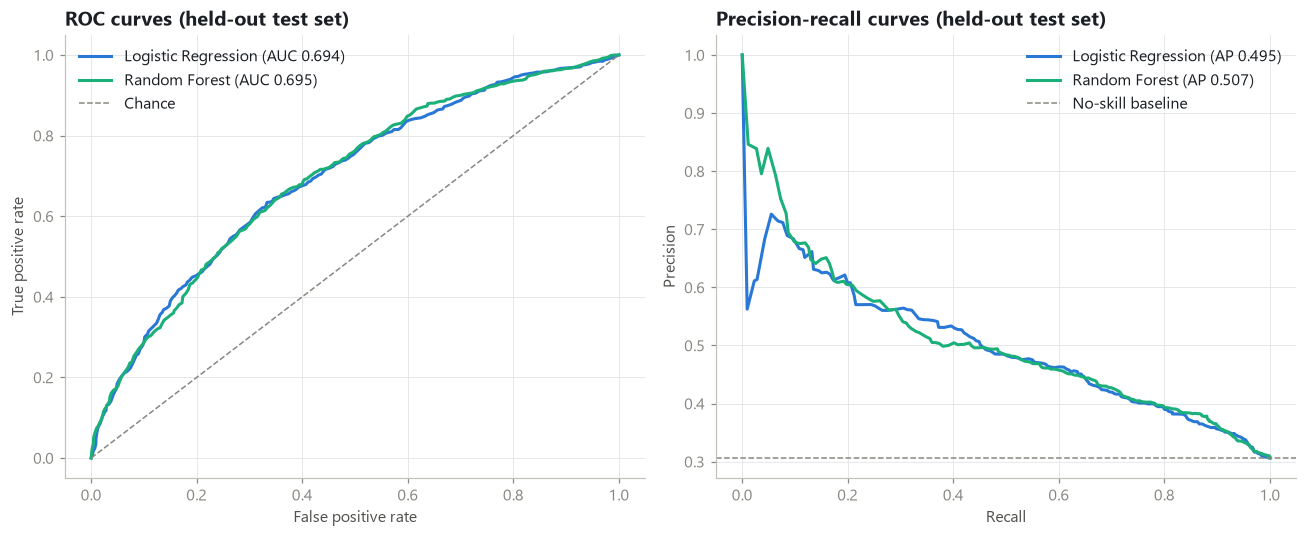

In [52]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for kind, color in [("logistic_regression", pl.BLUE), ("random_forest", pl.TEAL)]:
    m = meta["test_metrics"][kind]
    if m["roc_curve"] is None:
        print(m["note"])
        break
    axes[0].plot(m["roc_curve"]["fpr"], m["roc_curve"]["tpr"], color=color, linewidth=2,
                 label=f"{ml.MODEL_NAMES[kind]} (AUC {m['roc_auc']:.3f})")
    axes[1].plot(m["pr_curve"]["recall"], m["pr_curve"]["precision"], color=color, linewidth=2,
                 label=f"{ml.MODEL_NAMES[kind]} (AP {m['average_precision']:.3f})")
axes[0].plot([0, 1], [0, 1], linestyle="--", color=pl.MUTED, linewidth=1, label="Chance")
axes[1].axhline(selected_metrics["observed_positive_rate"], linestyle="--", color=pl.MUTED, linewidth=1, label="No-skill baseline")
axes[0].set(title="ROC curves (held-out test set)", xlabel="False positive rate", ylabel="True positive rate")
axes[1].set(title="Precision-recall curves (held-out test set)", xlabel="Recall", ylabel="Precision")
for ax in axes:
    ax.legend(loc="best")
fig.tight_layout()
pl.save_fig(fig, "09_roc_curves")
plt.show()

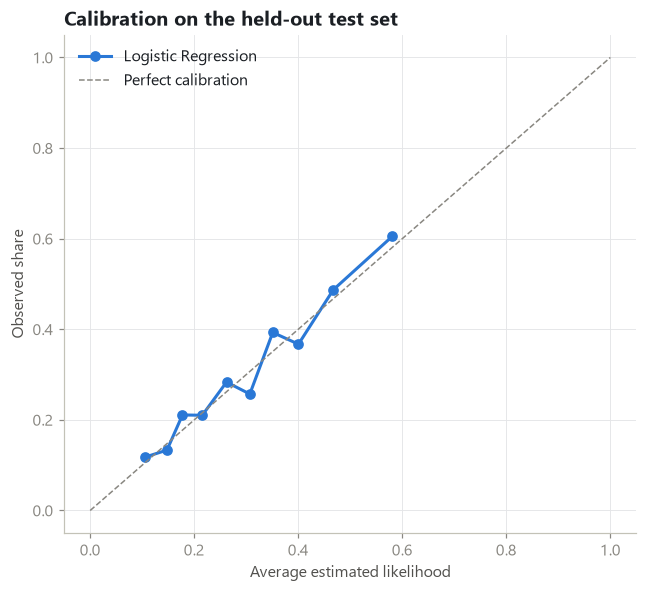

Calibration step: not needed (cross-validated ECE 0.010)


In [53]:
cal = selected_metrics["calibration_curve"]
fig, ax = plt.subplots(figsize=(6, 5.5))
if cal:
    ax.plot(cal["mean_predicted"], cal["observed"], marker="o", color=pl.BLUE, linewidth=2, label=meta["model_name"])
ax.plot([0, 1], [0, 1], linestyle="--", color=pl.MUTED, linewidth=1, label="Perfect calibration")
ax.set(title="Calibration on the held-out test set", xlabel="Average estimated likelihood", ylabel="Observed share")
ax.legend(loc="upper left")
fig.tight_layout()
pl.save_fig(fig, "11_calibration")
plt.show()
print("Calibration step:", meta["calibration"]["method"], f"(cross-validated ECE {meta['calibration']['cv_ece']:.3f})")

**Reading the curves:**
- **ROC curve:** the closer it bends to the top-left, the better the model separates the two classes.
- **Precision-recall curve:** focuses on the minority class.
- **Calibration plot:** points near the dashed line mean the displayed likelihoods match observed rates on average, which matters because the dashboard shows them.

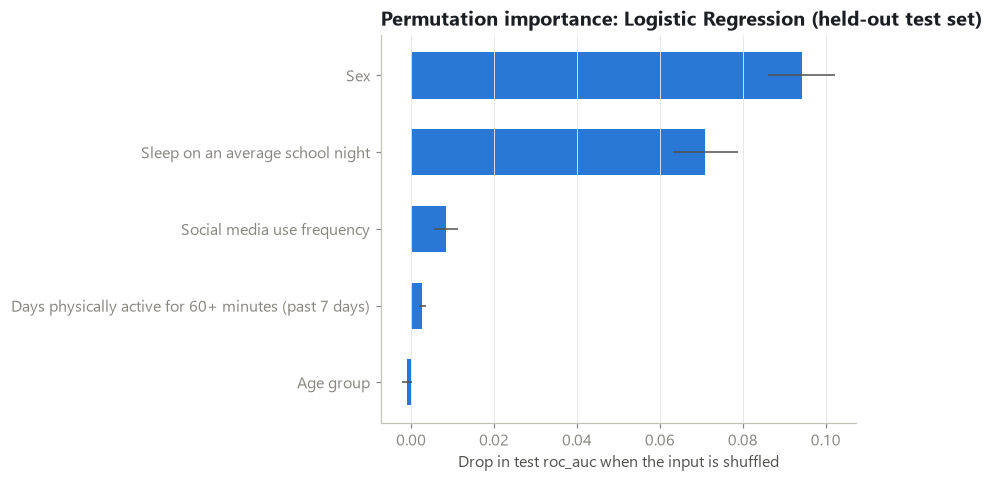

**Fairness check: test-set results by group** (flagged rate = share the model labels positive)

,variable,group,n,observed_rate,predicted_positive_rate,recall,precision
0,age_group,14 or younger,396,0.301,0.551,0.773,0.422
1,age_group,15,803,0.296,0.514,0.744,0.429
2,age_group,16,851,0.311,0.577,0.736,0.397
3,age_group,17,719,0.328,0.538,0.686,0.419
4,age_group,18 or older,354,0.274,0.483,0.680,0.386
5,sex,Female,1519,0.417,0.895,0.927,0.432
6,sex,Male,1597,0.200,0.187,0.303,0.326


In [54]:
importance = pd.DataFrame(meta["permutation_importance"]["features"]).sort_values("mean")
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(importance["label"], importance["mean"], xerr=importance["std"], color=pl.BLUE, height=0.6,
        error_kw={"ecolor": pl.INK_2, "elinewidth": 1})
ax.set(title=f"Permutation importance: {meta['model_name']} (held-out test set)",
       xlabel=f"Drop in test {meta['permutation_importance']['scoring']} when the input is shuffled")
ax.grid(axis="y", visible=False)
fig.tight_layout()
pl.save_fig(fig, "10_permutation_importance")
plt.show()

display(Markdown("**Fairness check: test-set results by group** (flagged rate = share the model labels positive)"))
pd.DataFrame(meta["subgroup_metrics"]).round(3)

**How to read importance:** permutation importance measures how much test performance drops when one input's values are shuffled. A large drop means the model relies on that input for *prediction*. It does **not** show that the input causes poor mental health.

**Demographic inputs:** sex and age describe group-level patterns in the survey, not personal faults. The fairness table shows whether the model flags groups at different rates or misses more cases in some groups.

In [55]:
example_profile = {"social_media_code": 8, "sleep_hours_approx": 5, "active_days": 1, "age_group": "16", "sex": "Female"}
print("Illustrative profile:", {ml.FEATURE_INFO[k]["label"]: ml.option_label(k, v) for k, v in example_profile.items()})

estimate = ml.predict(result["model"], meta, example_profile)
print(f"Estimated likelihood of reporting poor mental health (model's definition): {estimate['probability']:.1%}")
print(f"Model cut-off: {estimate['threshold']:.0%} -> {'at or above' if estimate['predicted_class'] else 'below'} the cut-off; "
      f"rate in the training data: {estimate['training_positive_rate']:.1%}")

display(Markdown("**What-if explanation** (change in the estimate if one answer were the most typical training answer)"))
display(pd.DataFrame(ml.explain_prediction(result["model"], meta, example_profile)).round(3))

suggestions = recs.generate_recommendations(example_profile)
display(Markdown("**Rule-based suggestions for this profile** (separate from the model's estimate)"))
for r in suggestions.recommendations:
    display(Markdown(f"- **{r.title}**: {r.action}  \n  *Why:* {r.reason}"))
for s in suggestions.strengths:
    print("Strength:", s)
print(suggestions.support_note)

Illustrative profile: {'Social media use frequency': 'More than once an hour', 'Sleep on an average school night': '5 hours', 'Days physically active for 60+ minutes (past 7 days)': '1 day', 'Age group': '16', 'Sex': 'Female'}
Estimated likelihood of reporting poor mental health (model's definition): 59.0%
Model cut-off: 27% -> at or above the cut-off; rate in the training data: 30.6%


**What-if explanation** (change in the estimate if one answer were the most typical training answer)

,feature,label,your_answer,typical_answer,probability_with_typical,difference
0,sex,Sex,Female,Male,0.350,0.240
1,sleep_hours_approx,Sleep on an average school night,5 hours,6 hours,0.508,0.082
2,social_media_code,Social media use frequency,More than once an hour,Several times a day,0.544,0.046
3,active_days,Days physically active for 60+ minutes (past 7...,1 day,4 days,0.566,0.024


**Rule-based suggestions for this profile** (separate from the model's estimate)

- **Add movement you enjoy**: Start small: pick an activity you like, such as walking, cycling, dancing or a sport with friends, and add it on two or three more days a week.  
  *Why:* You reported 1 active day in the past week; the CDC recommends at least 60 minutes of activity every day for ages 6-17. In this survey, more active students reported poor mental health somewhat less often (an association, not proof of cause).

- **Protect your sleep**: Keep a regular sleep and wake time, including weekends, and build a short wind-down routine before bed. A screen-free last half hour before sleep is one simple way to protect that routine.  
  *Why:* You reported 5 hours of sleep on school nights, below the CDC's guideline of 8-10 hours a night for teens aged 13-17. In this survey, shorter sleep went together with reporting poor mental health more often (an association, not proof of cause).

- **Make social media use more intentional**: Notice when and why you open apps. Turn off non-essential notifications and plan short app-free breaks, for example during homework, meals or time with friends.  
  *Why:* You reported using social media more than once an hour. In this survey, the most frequent users reported poor mental health more often. That is an association; it does not mean social media is harmful for you, and many frequent users feel fine.

If you often feel low, stressed, anxious or not like yourself, you don't have to handle it alone. Talk to someone you trust, such as a friend, family member, teacher or school counsellor, or contact a qualified health professional. In an emergency, contact your local emergency number.


**Limitations and ethical considerations of the model:**
- **Population:** it was trained on US high-school students surveyed in 2023. It is not validated for college students, adults or other countries.
- **Not a diagnosis:** the outcome is one self-reported survey question, not a clinical assessment. Never use the model to make decisions about real people.
- **Association, not cause:** the survey is cross-sectional, so a recommendation is a general healthy-habit suggestion based on guidelines, and is not promised to change the estimate.
- **Unweighted:** survey weights and the clustered design are not used, so the metrics describe the sample, not the nation.
- **Few inputs:** with only five inputs, most influences on mental health are missing, which limits how well the model can do.

The full list, saved with the model, is printed below.

In [56]:
for item in meta["limitations"]:
    print("-", item)

# Used by the summary in Section 16
best = meta["model_name"]
auc = selected_metrics["roc_auc"]
quality = ("not computable" if auc is None else "poor (close to chance)" if auc < 0.6 else "modest" if auc < 0.7
           else "acceptable" if auc < 0.8 else "good")

- Trained on US high-school students (about 14-18) surveyed in 2023; it may not apply to college students, adults or other countries.
- The outcome is a single self-reported survey question, not a clinical assessment. The model cannot diagnose anything.
- Associations only: the survey is cross-sectional, so the model shows which answers go together, not causes.
- Unweighted: the model describes the survey sample. Survey weights and the clustered design are not used, so metrics are not national estimates.
- Missing answers are imputed inside the pipeline (median or a 'Not answered' category, learned from training data only); 26% of labelled students skipped the social media question.
- Uses only five inputs; most influences on mental health (family, school, health, relationships) are not measured, so individual estimates are uncertain.
- Includes sex and age group, which carry group-level differences; these are not personal faults and the model must not be used to make decisions about r

## 16. Interpretation of findings

The summary below is **generated from the results computed above**; nothing in it is typed in by hand. Each statement describes an association in the 2023 YRBS sample, with its effect size.

In [57]:
def share_for(flag_col: str, freq_value: int) -> float:
    sub = df[au.is_level(df["social_media_frequent"], freq_value)]
    return au.weighted_share(sub[flag_col], sub["weight"])[0]


sm_or = odds.loc["social_media_frequent"]
findings = [
    f"**RQ1, social media use:** {frequent_pct:.1f}% of students (weighted) use social media several times "
    f"a day or more. The median category is '{median_cat}'.",
    f"**RQ2, sleep:** "
    f"{au.association_phrase(rho_sm_sleep, 'More frequent social media use', 'sleep hours', 'more sleep', 'less sleep')} "
    f"Frequent users vs others: "
    f"rank-biserial r = {t3['effect_size']:.3f} ({t3['effect']}); mean about {t3['mean_a']:.2f} h vs "
    f"{t3['mean_b']:.2f} h.",
    f"**RQ3, physical activity:** "
    f"{au.association_phrase(t5, 'Being active on more days', 'poor mental health', 'reporting poor mental health more often', 'reporting poor mental health less often')} "
    f"Active 5+ days vs poor mental health: Cramer's V = {t6['effect_size']:.3f} ({t6['effect']}); "
    f"adjusted odds ratio = {odds.loc['active_5plus', 'odds_ratio']:.2f}.",
    f"**RQ4, age:** Cramer's V for age group vs frequent use = {t7['effect_size']:.3f} ({t7['effect']}); "
    f"frequent use ranges from {freq_by_age['percent'].min():.1f}% to {freq_by_age['percent'].max():.1f}% "
    f"across age groups.",
    f"**RQ5, mental health:** poor mental health is reported by {share_for('poor_mental_health', 1):.1f}% of "
    f"frequent users vs {share_for('poor_mental_health', 0):.1f}% of less frequent users "
    f"(Cramer's V = {t1['effect_size']:.3f}, {t1['effect']}). Persistent sadness: "
    f"{share_for('sad_hopeless', 1):.1f}% vs {share_for('sad_hopeless', 0):.1f}% "
    f"(V = {t2['effect_size']:.3f}, {t2['effect']}). Adjusted odds ratio for frequent use = "
    f"{sm_or['odds_ratio']:.2f} (95% CI {sm_or['ci_low']:.2f}-{sm_or['ci_high']:.2f}).",
    f"**RQ6, correlations:** the strongest pair in the heatmap is {correlation_table.loc[0, 'x']} & "
    f"{correlation_table.loc[0, 'y']} (rho = {correlation_table.loc[0, 'spearman_rho']:.3f}, "
    f"{correlation_table.loc[0, 'effect']}).",
    f"**RQ7, prediction:** the best model ({best}) reaches a held-out test ROC-AUC of {auc:.3f} ({quality}).",
    f"**Multiple testing:** {int(summary_tests['significant_after_holm'].sum())} of {len(summary_tests)} "
    f"tests remain significant after the Holm correction.",
]
display(Markdown("\n\n".join(f"- {f}" for f in findings)))

- **RQ1, social media use:** 77.0% of students (weighted) use social media several times a day or more. The median category is 'Several times a day'.

- **RQ2, sleep:** More frequent social media use shows only a negligible association with sleep hours (Spearman rho = -0.07). Frequent users vs others: rank-biserial r = -0.065 (negligible); mean about 6.42 h vs 6.58 h.

- **RQ3, physical activity:** Being active on more days goes with reporting poor mental health less often (small association, Spearman rho = -0.12). Active 5+ days vs poor mental health: Cramer's V = 0.088 (negligible); adjusted odds ratio = 0.81.

- **RQ4, age:** Cramer's V for age group vs frequent use = 0.037 (negligible); frequent use ranges from 74.5% to 79.1% across age groups.

- **RQ5, mental health:** poor mental health is reported by 30.6% of frequent users vs 20.0% of less frequent users (Cramer's V = 0.090, negligible). Persistent sadness: 42.6% vs 31.9% (V = 0.091, negligible). Adjusted odds ratio for frequent use = 1.64 (95% CI 1.23-2.17).

- **RQ6, correlations:** the strongest pair in the heatmap is poor_mh_code & sad_hopeless (rho = 0.524, large).

- **RQ7, prediction:** the best model (Logistic Regression) reaches a held-out test ROC-AUC of 0.694 (modest).

- **Multiple testing:** 7 of 7 tests remain significant after the Holm correction.

**How to read these findings responsibly:**
- **Effect size matters more than significance.** With thousands of students, very small associations are "statistically significant". Words such as *negligible* or *small* tell you how much the groups actually differ.
- **Effect-size labels are conventions, not verdicts.** For yes/no outcomes, Cramér's V tends to be small even when the gap between groups is noticeable. So for RQ5, also look at the **difference in percentage points** and the **odds ratio**, and judge whether that gap matters in practice.
- **Direction is not cause.** If frequent users report poorer mental health, possible explanations include:
  1. social media affecting mood or sleep
  2. students who already feel worse using social media more
  3. other factors (stress, family, school, loneliness) driving both

  This dataset cannot separate these explanations.
- **Patterns across groups describe averages.** Many students in every group do not follow the overall pattern.

## 17. Limitations

1. **Variables not available.** The 2023 national YRBS has no measure of screen time, nighttime social media use, sleep quality or anxiety. Those analyses were skipped rather than approximated with invented data.
2. **Social media is measured as frequency, not duration.** "Several times a day" could mean 10 minutes or 6 hours.
3. **Proxy outcomes.** "Poor mental health" (Q84) and "persistent sadness" (Q26) are single self-report questions, not clinical diagnoses and not anxiety measures.
4. **Cross-sectional design.** All answers come from one moment in time, so the order of events and causation cannot be determined.
5. **Self-report.** Students may misremember or under- or over-report, especially on sensitive topics.
6. **Narrow age range.** About 14–18 years, all in school. The results do not generalise to adults or to young people not in school.
7. **Missing data.** Answers were not imputed. If students who skipped questions differ systematically from those who answered, the results may be biased. See the missingness checks in Sections 8 and 11.
8. **Survey design partly handled.** Weighted percentages use CDC weights, but the chi-square, Spearman, Mann–Whitney and Kruskal–Wallis tests ignore weights and clustering, so their p-values are too small. The regression uses weights and PSU clustering but not strata. A full design-based analysis would use dedicated survey software (for example R's `survey` package or SAS `PROC SURVEYLOGISTIC`).
9. **Approximate confidence intervals.** These use Kish's effective sample size and ignore clustering.
10. **Ordinal approximations.** `sleep_hours_approx` treats "4 or less" as 4 and "10 or more" as 10.
11. **Unmeasured factors.** Family situation, bullying, academic stress, loneliness and many other factors that may influence both social media use and mental health are not in the model.

Missing data for the key variables in the cleaned dataset:

In [58]:
(df[["social_media_code", "sleep_code", "active_days", "poor_mh_code", "sad_hopeless",
     "difficulty_concentrating"]].isna().mean() * 100).round(2).rename("missing %").to_frame()

,missing %
social_media_code,24.280
sleep_code,13.130
active_days,5.990
poor_mh_code,21.780
sad_hopeless,1.070
difficulty_concentrating,45.480


## 18. Conclusion and future scope

**Conclusion.** Using real, nationally representative CDC data, this notebook measured how social media use frequency, sleep, physical activity and age relate to self-reported mental health among US high-school students in 2023.

The direction and size of each association are reported in **Section 16**. Those values are computed from the data, so they are not repeated here as fixed text.

Throughout, results are described as **associations**: the survey design does not allow conclusions about cause and effect.

**Future scope:**
- **Use a dataset with the missing variables.** Daily screen-time hours (ideally measured by the device rather than self-reported), nighttime phone use, sleep quality (for example the Pittsburgh Sleep Quality Index) and a validated anxiety scale (for example GAD-7) would allow the original objectives 1, 3 and 6 to be tested.
- **Use longitudinal data.** Following the same students over time could show whether changes in social media use come before or after changes in mental health. One example is the Adolescent Brain Cognitive Development (ABCD) Study, which requires a data use agreement.
- **Do a full design-based analysis.** Account for strata, clusters and weights in all tests.
- **Repeat with the 2025 YRBS.** CDC lists 2025 national data on the same page; check its questionnaire first, since questions can change.
- **Run subgroup analyses.** Examine whether associations differ by sex or other characteristics.

## 19. References

1. Centers for Disease Control and Prevention. *Youth Risk Behavior Surveillance System (YRBSS): Data and Documentation.* https://www.cdc.gov/yrbs/data/index.html
2. Centers for Disease Control and Prevention. *2023 National YRBS Data User's Guide.* https://www.cdc.gov/yrbs/media/pdf/2023/2023_National_YRBS_Data_Users_Guide508.pdf
3. Centers for Disease Control and Prevention. *2023XXH SAS Input Program* and *Formats Program.* https://www.cdc.gov/yrbs/data/index.html
4. Centers for Disease Control and Prevention. Overview and Methods for the Youth Risk Behavior Surveillance System — United States, 2023. *MMWR Suppl* 2024;73(4). https://www.cdc.gov/mmwr/volumes/73/su/su7304a1.htm
5. Centers for Disease Control and Prevention. *MMWR Suppl* 2024;73(4): report on frequent social media use among high school students, YRBS 2023. https://www.cdc.gov/mmwr/volumes/73/su/su7304a3.htm
6. Centers for Disease Control and Prevention. *MMWR Suppl* 2024;73(4): report using the 2023 YRBS mental health, sleep and physical activity items. https://www.cdc.gov/mmwr/volumes/73/su/su7304a9.htm
7. Cohen J. *Statistical Power Analysis for the Behavioral Sciences.* 2nd ed. Lawrence Erlbaum; 1988.
8. Kish L. *Survey Sampling.* Wiley; 1965.
9. Holm S. A simple sequentially rejective multiple test procedure. *Scandinavian Journal of Statistics.* 1979;6(2):65–70.
10. Software: pandas, NumPy, SciPy, statsmodels, scikit-learn, Matplotlib and seaborn (versions printed in Section 6).

(Author lists for references 4–6 are on the linked pages; check them before citing formally.)